## peformance of models

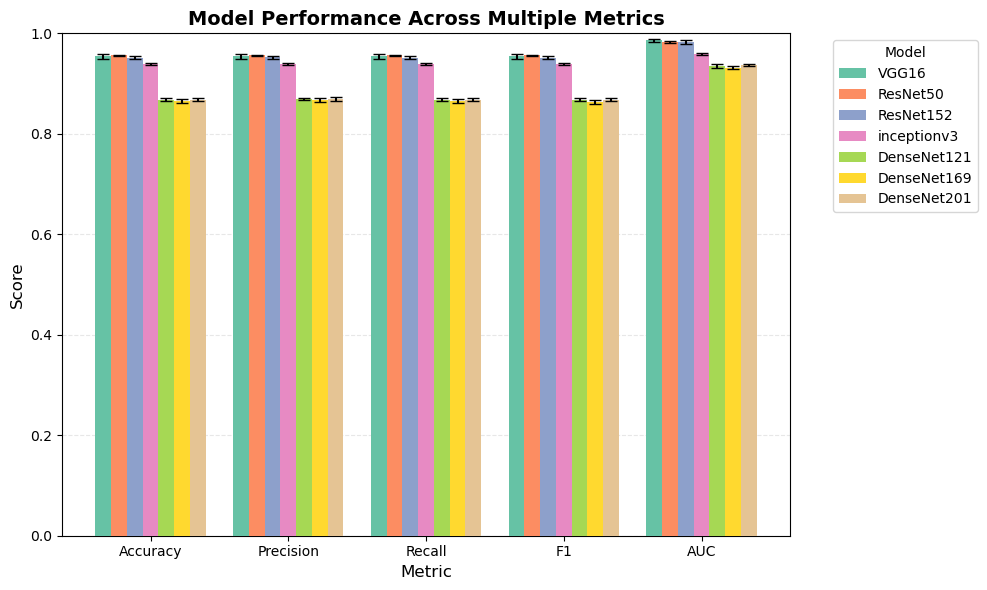

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 示例数据
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],

    "VGG16_mean": [0.9542, 0.9543, 0.9542, 0.9542, 0.9860],
    "VGG16_std":  [0.0046, 0.0045, 0.0046, 0.0046, 0.0027],

    "ResNet50_mean": [0.9561, 0.9561, 0.9561, 0.9561, 0.9830],
    "ResNet50_std":  [0.0017, 0.0017, 0.0017, 0.0017, 0.0022],

    "ResNet152_mean": [0.9518, 0.9520, 0.9518, 0.9518, 0.9826],
    "ResNet152_std":  [0.0027, 0.0026, 0.0027, 0.0027, 0.0033],

    "inceptionv3_mean": [0.9393, 0.9394, 0.9393, 0.9393, 0.9593],
    "inceptionv3_std":  [0.0024, 0.0023, 0.0024, 0.0024, 0.0023],

    "DenseNet121_mean": [0.8678, 0.8692, 0.8677, 0.8676, 0.9348],
    "DenseNet121_std":  [0.0028, 0.0019, 0.0028, 0.0029, 0.0032],

    "DenseNet169_mean": [0.8644, 0.8665, 0.8644, 0.8642, 0.9317],
    "DenseNet169_std":  [0.0039, 0.0038, 0.0039, 0.0039, 0.0035],
    
    "DenseNet201_mean": [0.8679, 0.8696, 0.8679, 0.8677, 0.9365],
    "DenseNet201_std":  [0.0033, 0.0045, 0.0034, 0.0033, 0.0015]
}
df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
model_order  = ["VGG16", "ResNet50", "ResNet152", "inceptionv3", "DenseNet121", "DenseNet169", "DenseNet201"]

# 取指定顺序的数据表
df = df.set_index("Metric").loc[metric_order]

# 分组条形图手工定位
x = np.arange(len(metric_order))            # 每个指标的x位置
group_width = 0.8                           # 一组柱子的总宽度
bar_width   = group_width / len(model_order)

palette = sns.color_palette("Set2", n_colors=len(model_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, model in enumerate(model_order):
    means = df[f"{model}_mean"].values
    stds  = df[f"{model}_std"].values
    # 每个模型在一组里的位置：左移半组宽，再按列序加偏移
    pos = x - group_width/2 + bar_width/2 + j*bar_width

    # 误差线裁剪到 [0, 1]，避免越界
    upper = np.minimum(1.0, means + stds) - means
    lower = means - np.maximum(0.0, means - stds)
    yerr  = np.vstack([lower, upper])  # 非对称误差

    ax.bar(pos, means,
           width=bar_width,
           label=model,
           color=palette[j],
           edgecolor="none",
           linewidth=0.6,
           yerr=yerr,
           capsize=4,
           zorder=3)

# 坐标与样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)  # 纵坐标 0~1
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("Model Performance Across Multiple Metrics", fontsize=14, weight="bold")
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

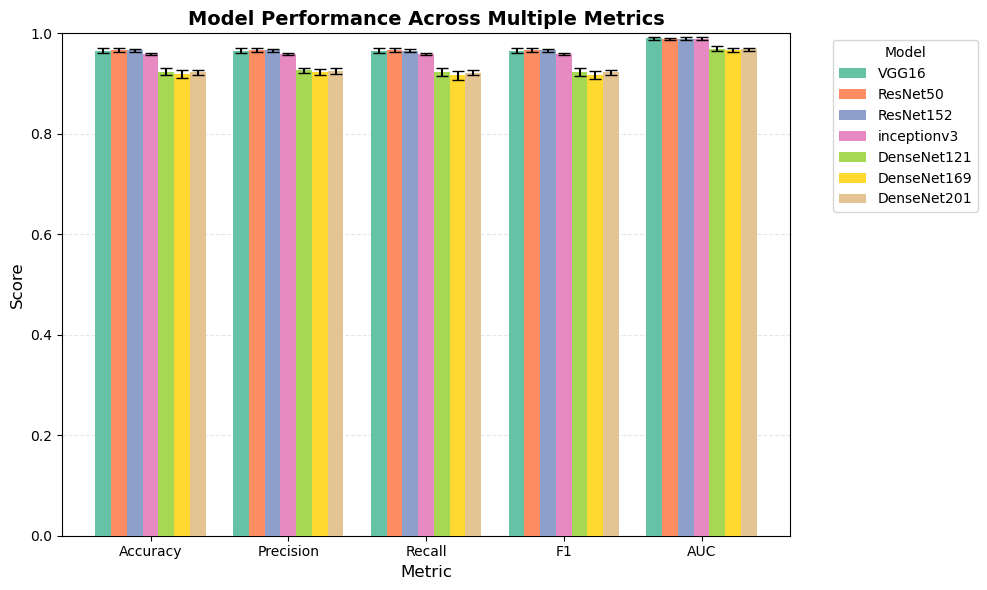

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 示例数据
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],

    "VGG16_mean": [0.9656, 0.9655, 0.9655, 0.9655, 0.9901],
    "VGG16_std":  [0.0052, 0.0051, 0.0052, 0.0052, 0.0029],

    "ResNet50_mean": [0.9668, 0.9670, 0.9665, 0.9667, 0.9891],
    "ResNet50_std":  [0.0040, 0.0040, 0.0040, 0.0040, 0.0023],

    "ResNet152_mean": [0.9662, 0.9664, 0.9658, 0.9661, 0.9897],
    "ResNet152_std":  [0.0027, 0.0026, 0.0027, 0.0027, 0.0023],

    "inceptionv3_mean": [0.9593, 0.9596, 0.9589, 0.9592, 0.9888],
    "inceptionv3_std":  [0.0023, 0.0020, 0.0025, 0.0023, 0.0030],

    "DenseNet121_mean": [0.9238, 0.9263, 0.9222, 0.9233, 0.9697],
    "DenseNet121_std":  [0.0073, 0.0055, 0.0080, 0.0075, 0.0041],

    "DenseNet169_mean": [0.9186, 0.9228, 0.9164, 0.9179, 0.9673],
    "DenseNet169_std":  [0.0079, 0.0066, 0.0084, 0.0081, 0.0041],
    
    "DenseNet201_mean": [0.9228, 0.9248, 0.9216, 0.9224, 0.9685],
    "DenseNet201_std":  [0.0049, 0.0056, 0.0049, 0.0049, 0.0032]
}
df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
model_order  = ["VGG16", "ResNet50", "ResNet152", "inceptionv3", "DenseNet121", "DenseNet169", "DenseNet201"]

# 取指定顺序的数据表
df = df.set_index("Metric").loc[metric_order]

# 分组条形图手工定位
x = np.arange(len(metric_order))            # 每个指标的x位置
group_width = 0.8                           # 一组柱子的总宽度
bar_width   = group_width / len(model_order)

palette = sns.color_palette("Set2", n_colors=len(model_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, model in enumerate(model_order):
    means = df[f"{model}_mean"].values
    stds  = df[f"{model}_std"].values
    # 每个模型在一组里的位置：左移半组宽，再按列序加偏移
    pos = x - group_width/2 + bar_width/2 + j*bar_width

    # 误差线裁剪到 [0, 1]，避免越界
    upper = np.minimum(1.0, means + stds) - means
    lower = means - np.maximum(0.0, means - stds)
    yerr  = np.vstack([lower, upper])  # 非对称误差

    ax.bar(pos, means,
           width=bar_width,
           label=model,
           color=palette[j],
           edgecolor="none",
           linewidth=0.6,
           yerr=yerr,
           capsize=4,
           zorder=3)

# 坐标与样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)  # 纵坐标 0~1
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("Model Performance Across Multiple Metrics", fontsize=14, weight="bold")
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

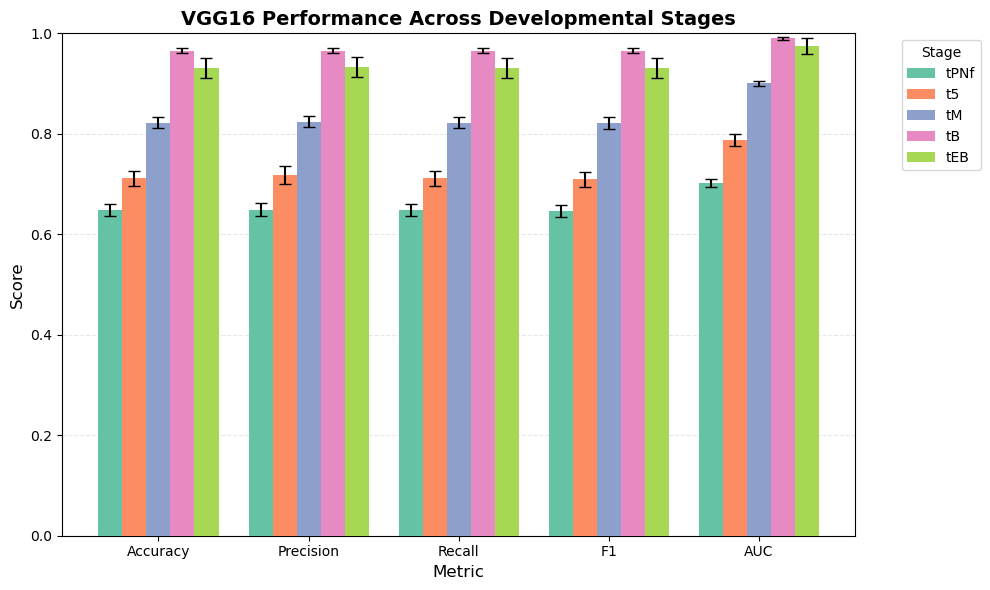

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ================================
# 你的数据（把 mean/std 换成你的）
# ================================
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],

    "tPNf_mean": [0.6478, 0.6491, 0.6478, 0.6471, 0.7024],
    "tPNf_std":  [0.0120, 0.0122, 0.0120, 0.0120, 0.0083],

    "t5_mean":   [0.7117, 0.7181, 0.7117, 0.7096, 0.7880],
    "t5_std":    [0.0152, 0.0184, 0.0152, 0.0153, 0.0117],

    "tM_mean":   [0.8223, 0.8243, 0.8223, 0.8220, 0.9002],
    "tM_std":    [0.0113, 0.0104, 0.0113, 0.0115, 0.0053],

    "tB_mean":   [0.9656, 0.9655, 0.9655, 0.9655, 0.9901],
    "tB_std":    [0.0052, 0.0051, 0.0052, 0.0052, 0.0029],

    "tEB_mean":  [0.9316, 0.9322, 0.9316, 0.9315, 0.9748],
    "tEB_std":   [0.0200, 0.0200, 0.0200, 0.0200, 0.0160]
}

df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
stage_order  = ["tPNf", "t5", "tM", "tB", "tEB"]

df = df.set_index("Metric").loc[metric_order]

# ================================
# 开始画图：每个 metric 一组，每组多个 stage
# ================================
x = np.arange(len(metric_order))
group_width = 0.8
bar_width   = group_width / len(stage_order)

palette = sns.color_palette("Set2", n_colors=len(stage_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, stage in enumerate(stage_order):
    mean_vals = df[f"{stage}_mean"].values
    std_vals  = df[f"{stage}_std"].values

    # 每个发育时期在一组中的相对位置
    pos = x - group_width/2 + bar_width/2 + j * bar_width

    # error bar（限制在 0~1 范围）
    upper = np.minimum(1.0, mean_vals + std_vals) - mean_vals
    lower = mean_vals - np.maximum(0.0, mean_vals - std_vals)
    yerr  = np.vstack([lower, upper])

    ax.bar(pos, mean_vals,
           width=bar_width,
           label=stage,
           color=palette[j],
           edgecolor="none",
           yerr=yerr,
           capsize=4,
           zorder=3)

# 样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("VGG16 Performance Across Developmental Stages",
             fontsize=14, weight="bold")

ax.legend(title="Stage", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig("VGG16_Performance_Across_Stages.pdf",
            format="pdf",
            bbox_inches="tight")
plt.show()



## 妊娠情况

In [18]:
import pandas as pd

# 读取 Excel 文件
df_2023 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2023-冷冻.xls")
df_2024 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2024-冷冻.xls")
df_2025 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2025-冷冻.xls")

df_all = pd.concat([df_2023, df_2024, df_2025], ignore_index=True)

keep_cols = [
    "女病人ID",
    "ARTID",
    "年龄",
    "Bmi(新鲜周期)",
    "移植胚胎存活细胞数1",
    "移植胚胎存活细胞数2",
    "移植数",
    "妊娠结局", 
    "胎儿数"
]

df_selected = df_all[[col for col in keep_cols if col in df_all.columns]]

# === 步骤 1: 仅保留 移植胚胎存活细胞数1 > 20 的行 ===
df_selected.loc[:, "移植胚胎存活细胞数1"] = (
    pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce")
    .astype("Int64")
)
df_selected = df_selected[pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce") > 20]

# === 步骤 2: 将 移植胚胎存活细胞数1 转为字符型 ===
df_selected["移植胚胎存活细胞数1"] = df_selected["移植胚胎存活细胞数1"].astype(str)

# === 步骤 3: 保留 胎儿数 == 0 或 胎儿数 == 移植数 的行 ===
df_selected["胎儿数"] = pd.to_numeric(df_selected["胎儿数"], errors="coerce")
df_selected["移植数"] = pd.to_numeric(df_selected["移植数"], errors="coerce")

df_filtered = df_selected[
    (df_selected["胎儿数"] == 0) |
    (df_selected["胎儿数"] == df_selected["移植数"])
].copy()

df_filtered = df_filtered.dropna(subset=["妊娠结局"]).copy()
# === 输出结果 ===
print(df_filtered.shape)
print(df_filtered.head)

(2747, 9)
<bound method NDFrame.head of        女病人ID   ARTID    年龄  Bmi(新鲜周期) 移植胚胎存活细胞数1  移植胚胎存活细胞数2  移植数  妊娠结局  胎儿数
1     138598  247840  31.5      36.21        411         NaN    1  临床妊娠    0
2     138598  268488  31.9      36.21        421         NaN    1  临床妊娠    1
3     285001  255700  25.8      36.05        411         NaN    1  临床妊娠    1
5     278932  247102  26.8      34.85        421         NaN    1  临床妊娠    1
6     263319  225820  33.6      33.50        423         NaN    1  临床妊娠    1
...      ...     ...   ...        ...        ...         ...  ...   ...  ...
3688  234340  369002  35.3      19.53        412         NaN    1   未妊娠    0
3691  305431  369547  30.6      18.29        422         NaN    1  生化妊娠    0
3699  289487  370440  36.5      24.09        411         NaN    1  生化妊娠    0
3703  296780  371221  39.8      23.44        323         NaN    1   未妊娠    0
3706  318372  371961  28.9      18.37        411         NaN    1   未妊娠    0

[2747 rows x 9 columns]>


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_10050/529606114.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '<IntegerArray>
[  7, 411, 421, 411,  12, 421, 423, 421, 412, 411,
 ...
 412, 323, 411, 411,   7, 323, 312, 323, 423, 411]
Length: 3723, dtype: Int64' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_selected.loc[:, "移植胚胎存活细胞数1"] = (


In [19]:
import pandas as pd

# =========================
# 1️⃣ 数据类型与过滤
# =========================

df = df_filtered.copy()

df["移植胚胎存活细胞数1"] = df["移植胚胎存活细胞数1"].astype(str)
df["妊娠结局"] = df["妊娠结局"].astype(str)

df = df[df["移植胚胎存活细胞数1"].str.len() >= 3].copy()

# =========================
# 2️⃣ 先把 Expansion=6 → 5（关键步骤！！）
# =========================

def normalize_code(code):
    code = str(code)
    if len(code) != 3:
        return None
    # 第一位是 expansion
    if code[0] == "6":
        return "5" + code[1:]
    return code

df["norm_code"] = df["移植胚胎存活细胞数1"].apply(normalize_code)

# =========================
# 3️⃣ norm_code → 囊胚等级
# =========================

def convert_to_grade(code):
    mapping = {"1": "A", "2": "B", "3": "C"}
    if code is None or len(code) != 3:
        return None
    return f"{code[0]}{mapping.get(code[1])}{mapping.get(code[2])}"

df["囊胚等级"] = df["norm_code"].apply(convert_to_grade)

df["Expansion"] = df["囊胚等级"].str[0]
df["ICM"] = df["囊胚等级"].str[1]
df["TE"] = df["囊胚等级"].str[2]

# =========================
# 4️⃣ 现在再统计（5 和 6 已真正合并）
# =========================

preg_stats = (
    df
    .groupby(["囊胚等级", "Expansion", "ICM", "TE"])
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)

preg_stats["妊娠概率"] = preg_stats["临床妊娠数"] / preg_stats["总数"] * 100

preg_stats = preg_stats.sort_values("妊娠概率", ascending=False)

# =========================
# 5️⃣ 输出
# =========================

print("各胚胎质量对应妊娠概率（Expansion=6 已真正合并为 5）：")
print(preg_stats)

各胚胎质量对应妊娠概率（Expansion=6 已真正合并为 5）：
   囊胚等级 Expansion ICM TE   总数  临床妊娠数       妊娠概率
15  5AA         5   A  A   25     21  84.000000
18  5BA         5   B  A    4      3  75.000000
4   3BA         3   B  A    4      3  75.000000
7   4AA         4   A  A  990    713  72.020202
10  4BA         4   B  A  105     74  70.476190
8   4AB         4   A  B  425    279  65.647059
1   3AA         3   A  A   17     11  64.705882
19  5BB         5   B  B   12      7  58.333333
2   3AB         3   A  B   55     31  56.363636
9   4AC         4   A  C   32     18  56.250000
11  4BB         4   B  B  315    177  56.190476
5   3BB         3   B  B  140     62  44.285714
12  4BC         4   B  C  398    172  43.216080
20  5BC         5   B  C   12      5  41.666667
16  5AB         5   A  B    5      2  40.000000
6   3BC         3   B  C  191     72  37.696335
3   3AC         3   A  C    6      2  33.333333
14  4CC         4   C  C    5      1  20.000000
0   2BC         2   B  C    1      0   0.000000
17  5

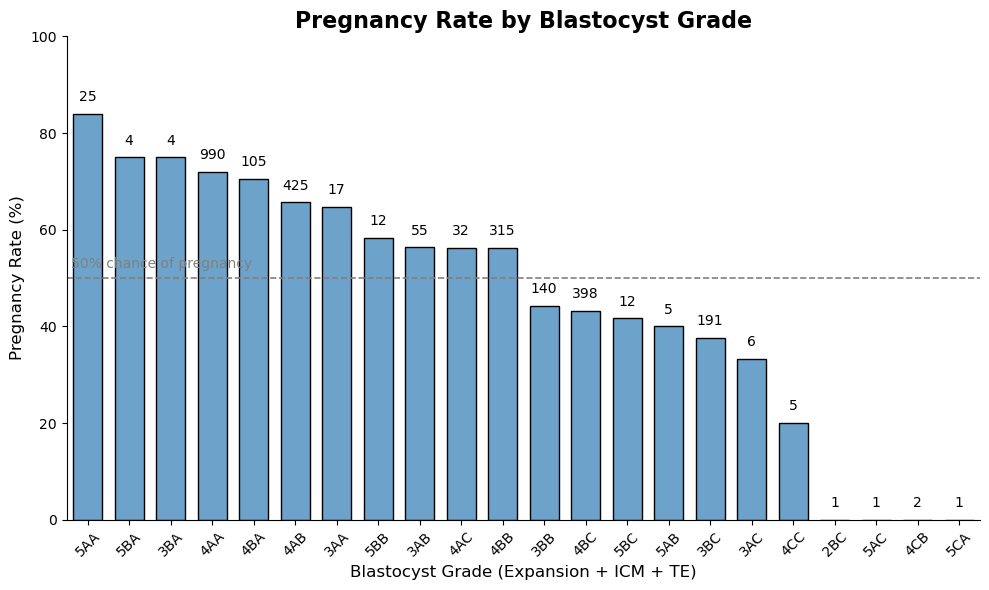

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6))

bar_color = "#5DA5DA"  # 清爽蓝，可换成别的十六进制颜色

sns.barplot(
    data=preg_stats,
    x="囊胚等级",
    y="妊娠概率",
    color=bar_color,
    edgecolor="black",
    width=0.7,
    ax=ax
)

# --- Titles and labels (English) ---
ax.set_title("Pregnancy Rate by Blastocyst Grade", fontsize=16, fontweight="bold")
ax.set_xlabel("Blastocyst Grade (Expansion + ICM + TE)", fontsize=12)
ax.set_ylabel("Pregnancy Rate (%)", fontsize=12)

# --- Add a 50% reference line ---
ax.set_ylim(0, 100)
ax.axhline(50, linestyle="--", linewidth=1.2, color="gray")
ax.text(
    x=-0.4, y=52, s="50% chance of pregnancy", color="gray",
    fontsize=10
)

categories = [t.get_text() for t in ax.get_xticklabels()]
counts = (
    preg_stats.set_index("囊胚等级")
              .reindex(categories)["总数"]
              .fillna(0).astype(int)
    .tolist()
)

for patch, n in zip(ax.patches, counts):
    x = patch.get_x() + patch.get_width() / 2.0   # 柱子中心
    y = patch.get_height()                        # 柱子高度（=妊娠率）
    y_label = min(y + 2, 98)                      # 往上抬一点，且不超出顶部
    ax.text(x, y_label, n, ha="center", va="bottom",
            fontsize=10, color="black")
# --- Style ---
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.tight_layout()
plt.savefig(
    "Pregnancy_rate_by_blastocyst_grade.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

✅ 各质量类别妊娠成功率：
        Quality  Total  Pregnant  Pregnancy Rate (%)
1  Good-quality   1630      1137           69.754601
0  Fair-quality    467       246           52.676660
2  Poor-quality    649       270           41.602465


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_10050/2387136365.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


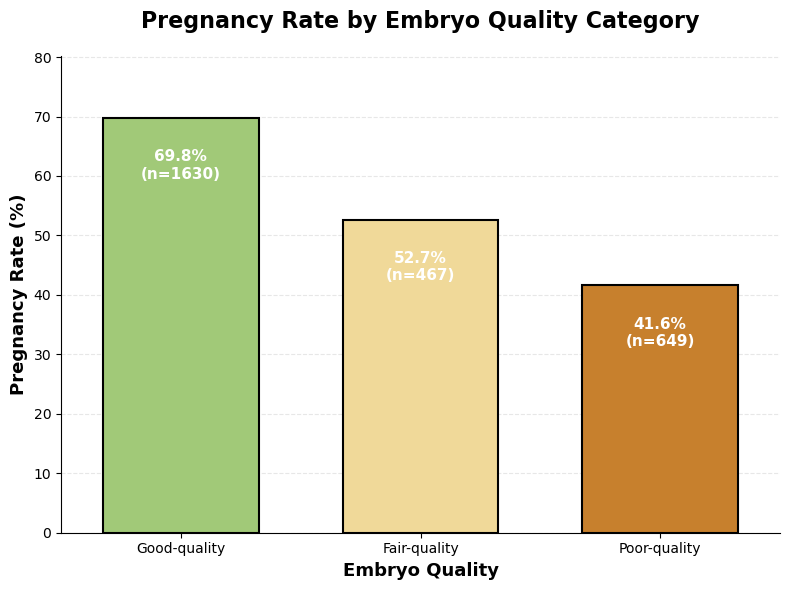

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 假设已有 preg_stats，包含列 ["囊胚等级", "总数", "临床妊娠数", "妊娠概率"]

# -------------------------------
# 1️⃣ 分类函数
# -------------------------------
def classify_quality(grade):
    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"
    expansion, icm, te = grade[0], grade[1], grade[2]

    # Fair-quality (exact matches)
    if grade in ["3BB","4BB", "5BB"]:
        return "Fair-quality"
    # Good-quality: extension ≥3 and (AA or AB or BA)
    elif expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    else:
        return "Poor-quality"

# -------------------------------
# 2️⃣ 添加分类列
# -------------------------------
preg_stats["Quality"] = preg_stats["囊胚等级"].apply(classify_quality)

# -------------------------------
# 3️⃣ 按 Quality 统计妊娠率
# -------------------------------
quality_stats = (
    preg_stats
    .groupby("Quality")
    .agg(
        Total=("总数", "sum"),
        Pregnant=("临床妊娠数", "sum")
    )
    .reset_index()
)
quality_stats["Pregnancy Rate (%)"] = quality_stats["Pregnant"] / quality_stats["Total"] * 100

# 🔥 定义质量顺序（从好到差）
quality_order = ["Good-quality", "Fair-quality", "Poor-quality"]
quality_stats["Quality"] = pd.Categorical(
    quality_stats["Quality"],
    categories=quality_order,
    ordered=True
)
quality_stats = quality_stats.sort_values("Quality")

print("✅ 各质量类别妊娠成功率：")
print(quality_stats)

# -------------------------------
# 4️⃣ 绘图
# -------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# 🎨 配色：绿色(Good) → 黄色(Fair) → 橙色(Poor)
palette = ["#A1D76A", "#FEE08B", "#E08214"] 

sns.barplot(
    data=quality_stats,
    x="Quality",
    y="Pregnancy Rate (%)",
    palette=palette,
    edgecolor="black",
    linewidth=1.5,
    width=0.65,
    ax=ax,
    order=quality_order  # 🔥 强制顺序
)

# 🏷️ 添加数值标签（优化位置）
for i, row in quality_stats.iterrows():
    rate = row["Pregnancy Rate (%)"]
    total = int(row["Total"])

    # 📍 标签位置自适应：柱子高时放内部，低时放外部
    if rate > 15:
        y_pos = rate - 8  # 放在柱子内部
        color = "white"
        weight = "bold"
    else:
        y_pos = rate + 3  # 放在柱子上方
        color = "black"
        weight = "normal"

    ax.text(
        quality_order.index(row["Quality"]),  # x位置
        y_pos,
        f"{rate:.1f}%\n(n={total})",
        ha="center",
        va="center" if rate > 15 else "bottom",
        fontsize=11,
        color=color,
        weight=weight
    )

# -------------------------------
# 5️⃣ 美化
# -------------------------------
ax.set_title("Pregnancy Rate by Embryo Quality Category",
             fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("Embryo Quality", fontsize=13, fontweight="bold")
ax.set_ylabel("Pregnancy Rate (%)", fontsize=13, fontweight="bold")
ax.set_ylim(0, max(quality_stats["Pregnancy Rate (%)"]) * 1.15)  # 动态上限

# 🎯 网格线（仅横向）
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.savefig(
    "Pregnancy_rate_by_embryo_quality.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()


In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ===============================
# 1️⃣ 数据预处理
# ===============================
# 确保类型正确
df_filtered["移植胚胎存活细胞数1"] = df_filtered["移植胚胎存活细胞数1"].astype(str)
df_filtered["妊娠结局"] = df_filtered["妊娠结局"].astype(str)

# 仅保留长度≥3的编码（如 411、422 等）
df_filtered = df_filtered[df_filtered["移植胚胎存活细胞数1"].str.len() >= 3].copy()

# ===============================
# 2️⃣ 数字编码 → 囊胚等级（4AA 等）
# ===============================
def convert_to_grade(code):
    code = str(code)
    if len(code) != 3:
        return None
    mapping = {"1": "A", "2": "B", "3": "C"}
    first = code[0]         # 扩张度
    second = mapping.get(code[1], "?")  # ICM
    third = mapping.get(code[2], "?")   # TE
    return f"{first}{second}{third}"

df_filtered["囊胚等级"] = df_filtered["移植胚胎存活细胞数1"].apply(convert_to_grade)

# ===============================
# 3️⃣ 囊胚等级 → 质量分类
# ===============================
def classify_quality(grade):
    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"
    expansion, icm, te = grade[0], grade[1], grade[2]

    # Fair-quality（中等质量）
    if grade in ["3BB", "4BB", "5BB"]:
        return "Fair-quality"
    # Good-quality：扩张度 ≥3 且 (AA / AB / BA)
    elif expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    else:
        return "Poor-quality"

df_filtered["Quality"] = df_filtered["囊胚等级"].apply(classify_quality)

# ===============================
# 4️⃣ 保存完整表格（每条记录带 Quality）
# ===============================
df_filtered.to_csv("Embryo_FullStats_withQuality.csv", index=False, encoding="utf-8-sig")

## 年龄情况

✅ 各年龄段统计：
     年龄段    人数        百分比
0  18-24    91   2.091473
1  25-29   937  21.535279
2  30-34  1742  40.036773
3  35-39  1063  24.431165
4  40-44   455  10.457366
5    ≥45    63   1.447943


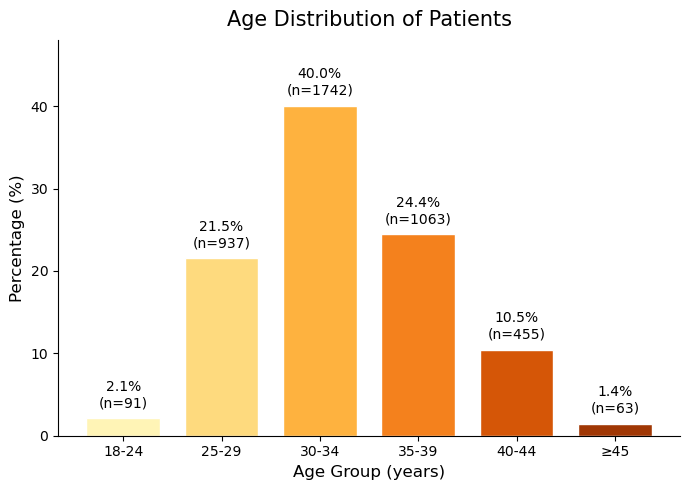

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 读取与清洗数据
# ==============================
df_age = pd.read_csv("/Users/lzz/Documents/GitHub/IVF_AI/SlidePatientBirthDates.csv")

df_age["Age"] = pd.to_numeric(df_age["Age"], errors="coerce")
df_age = df_age[df_age["Age"].notna() & (df_age["Age"] >= 18) & (df_age["Age"] <= 100)].copy()

# ==============================
# 2️⃣ 按年龄区间分组
# ==============================
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "≥45"]
df_age["年龄段"] = pd.cut(df_age["Age"], bins=bins, labels=labels, right=False)

# ==============================
# 3️⃣ 统计每个年龄段的数量与百分比
# ==============================
age_stats = (
    df_age["年龄段"]
    .value_counts()
    .sort_index()
    .reset_index()
)
age_stats.columns = ["年龄段", "人数"]
age_stats["百分比"] = age_stats["人数"] / age_stats["人数"].sum() * 100

print("✅ 各年龄段统计：")
print(age_stats)

# ==============================
# 4️⃣ 设置配色
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))

# ==============================
# 5️⃣ 绘图
# ==============================
plt.figure(figsize=(7, 5))
bars = plt.bar(
    age_stats["年龄段"],
    age_stats["百分比"],
    color=colors,
    edgecolor="white",
    width=0.75
)

# ==============================
# 6️⃣ 美化图形
# ==============================
plt.title("Age Distribution of Patients", fontsize=15, pad=10)
plt.xlabel("Age Group (years)", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.ylim(0, age_stats["百分比"].max() * 1.2)

# 添加百分比与人数标签
for i, row in age_stats.iterrows():
    plt.text(
        i, row["百分比"] + 1,
        f"{row['百分比']:.1f}%\n(n={row['人数']})",
        ha='center', va='bottom', fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.savefig(
    "/Users/lzz/Documents/GitHub/IVF_AI/Figure_Age_Distribution.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

✅ 各年龄段妊娠率：
     年龄段    总数  临床妊娠数     妊娠率(%)
0  18-24    73     51  69.863014
1  25-29   686    479  69.825073
2  30-34  1131    730  64.544651
3  35-39   625    333  53.280000
4  40-44   223     59  26.457399
5   >=45     8      1  12.500000


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_10050/4174575571.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("年龄段")


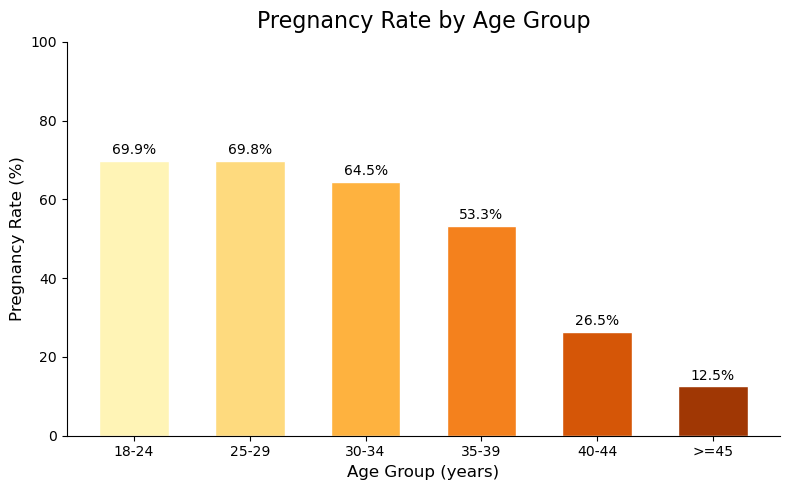

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 数据准备
# ==============================
df_filtered["年龄"] = pd.to_numeric(df_filtered["年龄"], errors="coerce")

# 年龄区间
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", ">=45"]
df_filtered["年龄段"] = pd.cut(df_filtered["年龄"], bins=bins, labels=labels, right=False)

# 各年龄段妊娠率
age_stats = (
    df_filtered
    .groupby("年龄段")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)
age_stats["妊娠率(%)"] = age_stats["临床妊娠数"] / age_stats["总数"] * 100

print("✅ 各年龄段妊娠率：")
print(age_stats)

# ==============================
# 2️⃣ 自定义渐变配色（黄色→橙色）
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))  # 黄色到橙棕色渐变
# 或者更亮：sns.color_palette("YlOrRd", n_colors=len(age_stats))

# ==============================
# 3️⃣ 绘图
# ==============================
plt.figure(figsize=(8, 5))

bars = plt.bar(
    age_stats["年龄段"],
    age_stats["妊娠率(%)"],
    color=colors,
    edgecolor="white",
    width=0.6
)

# ==============================
# 4️⃣ 美化
# ==============================
plt.title("Pregnancy Rate by Age Group", fontsize=16, pad=10)
plt.xlabel("Age Group (years)", fontsize=12)
plt.ylabel("Pregnancy Rate (%)", fontsize=12)
plt.ylim(0, 100)

# 添加柱顶数值
for i, row in age_stats.iterrows():
    plt.text(i, row["妊娠率(%)"] + 1, f"{row['妊娠率(%)']:.1f}%", 
             ha='center', va='bottom', fontsize=10)

# 优化外观
sns.despine()
plt.tight_layout()
plt.savefig(
    "/Users/lzz/Documents/GitHub/IVF_AI/Figure_Pregnancy_Rate_by_Age.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

## CHAID

In [25]:
import pandas as pd
import numpy as np
import re
from CHAID import Tree

# ==============================
# 1️⃣ 数据加载与清洗
# ==============================
df = df_filtered.copy()

df["年龄"] = pd.to_numeric(df["年龄"], errors="coerce")
df["Bmi(新鲜周期)"] = pd.to_numeric(df["Bmi(新鲜周期)"], errors="coerce")

# 保留有效妊娠结局
df["Pregnancy"] = (df["妊娠结局"] == "临床妊娠").astype(int)

print(df.shape)

# ==============================
# 2️⃣ 胚胎编码规范化
# ==============================
def to_abc_grade(x):
    if pd.isna(x): return None
    s = str(x).strip().upper()
    s = re.sub(r'[^0-9A-Z]', '', s)
    if len(s) < 3 or not s[0].isdigit():
        return None
    exp = s[0]
    tail = s[1:]
    if len(tail) < 2:
        return None
    c2, c3 = tail[0], tail[1]
    d2l = {'1': 'A', '2': 'B', '3': 'C'}
    def norm_one(ch):
        if ch in d2l: return d2l[ch]
        if ch in ('A','B','C'): return ch
        return None
    icm, te = norm_one(c2), norm_one(c3)
    if icm is None or te is None:
        return None
    return f"{exp}{icm}{te}"

df["GradeABC"] = df["移植胚胎存活细胞数1"].apply(to_abc_grade)
df = df[df["GradeABC"].notna()].copy()

# ==============================
# 3️⃣ 按规则划分胚胎质量
# ==============================
FAIR_SET = {"3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"}

def classify_quality(grade_abc):
    exp, icm, te = grade_abc[0], grade_abc[1], grade_abc[2]
    if grade_abc in FAIR_SET:
        return "Fair-quality"
    if int(exp) >= 3 and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    return "Poor-quality"

df["Quality"] = df["GradeABC"].apply(classify_quality)
df = df[df["Quality"].isin(["Good-quality", "Poor-quality"])].copy()
df["Quality"] = df["Quality"].astype("category")

# ==============================
# 4️⃣ 年龄分组
# ==============================
bins = [-np.inf, 30, 32, 34, 36, 38, 40, np.inf]
labels = ["≤30", "31–32", "33–34", "35–36", "37–38", "39–40", "≥41"]
df["AgeGroup"] = pd.cut(df["年龄"], bins=bins, labels=labels, right=True)
df = df[df["AgeGroup"].notna()].copy()
df["AgeGroup"] = df["AgeGroup"].astype("category")

# ==============================
# 5️⃣ BMI 分组（根据 WHO 标准）
# ==============================
def bmi_group(bmi):
    if pd.isna(bmi): return None
    if bmi < 18.5: return "Underweight"
    elif bmi < 25: return "Normal"
    else: return "Overweight"

df["BMIgroup"] = df["Bmi(新鲜周期)"].apply(bmi_group)
df = df[df["BMIgroup"].notna()].copy()
df["BMIgroup"] = df["BMIgroup"].astype("category")

print("\n✅ 胚胎质量分布：")
print(df["Quality"].value_counts())
print("\n✅ 年龄组分布：")
print(df["AgeGroup"].value_counts())
print("\n✅ BMI 分布：")
print(df["BMIgroup"].value_counts())

# ==============================
# 6️⃣ 构建 CHAID 决策树
# ==============================
variables = {
    'AgeGroup': 'nominal',
    'Quality': 'nominal',
    'BMIgroup': 'nominal'
}

chaid_tree = Tree.from_pandas_df(
    df,
    variables,
    'Pregnancy',
    max_depth=5,
    min_child_node_size=20
)

# ==============================
# 7️⃣ 输出结果
# ==============================
print("\n📊 CHAID 决策树结构：")
chaid_tree.print_tree()

(2746, 13)

✅ 胚胎质量分布：
Quality
Good-quality    1610
Poor-quality     589
Name: count, dtype: int64

✅ 年龄组分布：
AgeGroup
≤30      657
31–32    407
33–34    341
35–36    336
37–38    190
≥41      144
39–40    124
Name: count, dtype: int64

✅ BMI 分布：
BMIgroup
Normal         1338
Overweight      479
Underweight     230
Obese           152
Name: count, dtype: int64

📊 CHAID 决策树结构：
([], {0: 825.0, 1: 1374.0}, (Quality, p=2.4788806412139664e-32, score=140.14157067916878, groups=[['Good-quality'], ['Poor-quality']]), dof=1))
|-- (['Good-quality'], {0: 485.0, 1: 1125.0}, (AgeGroup, p=7.275884608101298e-16, score=73.5871247089839, groups=[['31–32', '≤30'], ['33–34', '35–36'], ['37–38', '39–40'], ['≥41']]), dof=3))
|   |-- (['31–32', '≤30'], {0: 193.0, 1: 631.0}, <Invalid Chaid Split> - p-value greater than alpha merge)
|   |-- (['33–34', '35–36'], {0: 156.0, 1: 342.0}, <Invalid Chaid Split> - p-value greater than alpha merge)
|   |-- (['37–38', '39–40'], {0: 86.0, 1: 125.0}, <Invalid Chaid Split> -

/Users/lzz/anaconda3/lib/python3.11/site-packages/CHAID/graph.py:13: UserWarning: Imports of optional packages needed to generate graphs failed. Please install with the "graph" option.
  warnings.warn(UserWarning('Imports of optional packages needed to generate graphs failed. Please install with the "graph" option.'))


In [26]:
from graphviz import Digraph

# ========= 辅助函数 =========
def success_rate(node_dict):
    """计算并格式化成功率"""
    total = sum(node_dict.values())
    success = node_dict.get(1, 0)
    rate = 100 * success / total if total > 0 else 0
    return f"{rate:.1f}%"

# ========= 样式定义 =========
styles = {
    "root": {"shape": "ellipse", "style": "filled,bold", "fillcolor": "#FFD166", "color": "#E07A5F", "fontname": "Helvetica-Bold"},
    "split": {"shape": "box", "style": "rounded,filled", "fillcolor": "#B5EAD7", "color": "#4E878C", "fontname": "Helvetica"},
    "leaf": {"shape": "circle", "style": "filled", "fillcolor": "#F9F9F9", "color": "#999999", "fontname": "Helvetica"},
}

# ========= 初始化图 =========
dot = Digraph('CHAID_Tree', format='pdf')
dot.attr(rankdir='TB', splines='curved', bgcolor='white', sep='0.5', nodesep='0.8', ranksep='1.2')
dot.attr('node', fontsize='9', width='0.6', height='0.4')
dot.attr('edge', fontsize='8')

# ========= 根节点 =========
root_data = {0: 830, 1: 1375}
dot.node('root', f'Quality\np = 9.52×10⁻³³', **styles["root"])

# ========= 第一层 =========
gq_data = {0: 487, 1: 1126}
pq_data = {0: 343, 1: 249}
dot.node('gq', f'Age\np = 1.50×10⁻¹⁶', **styles["split"])
dot.node('pq', f'Age\np = 5.63×10⁻⁶', **styles["split"])
dot.edge('root', 'gq', label='Good-quality', color="#E07A5F", penwidth='2')
dot.edge('root', 'pq', label='Poor-quality', color="#E07A5F", penwidth='2')

# ========= 第二层 (Good-quality) =========
dot.node('gq1', success_rate({0:265,1:812}), **styles["leaf"])
dot.node('gq2', success_rate({0:171,1:287}), **styles["leaf"])
dot.node('gq3', success_rate({0:51,1:27}), **styles["leaf"])
dot.edge('gq', 'gq1', label='Age ≤34', color="#4E878C")
dot.edge('gq', 'gq2', label='Age 35–40', color="#4E878C")
dot.edge('gq', 'gq3', label='Age ≥41', color="#4E878C")

# ========= 第二层 (Poor-quality) =========
dot.node('pq1', success_rate({0:105,1:81}), **styles["leaf"])
dot.node('pq2', f'BMI\np = 0.0055', **styles["split"])
dot.node('pq3', success_rate({0:90,1:105}), **styles["leaf"])
dot.edge('pq', 'pq1', label='Age 31–34', color="#4E878C")
dot.edge('pq', 'pq2', label='Age ≥39 or 35-36', color="#4E878C")
dot.edge('pq', 'pq3', label='Age ≤30 or 37–38', color="#4E878C")

# ========= 第三层 (BMI 子节点) =========
dot.node('pq2a', success_rate({0:124,1:42}), **styles["leaf"])
dot.node('pq2b', success_rate({0:24,1:21}), **styles["leaf"])
dot.edge('pq2', 'pq2a', label='BMI Normal/Under/Obese', color="#6A4C93")
dot.edge('pq2', 'pq2b', label='BMI Overweight', color="#6A4C93")

# ========= 输出 =========
output_path = dot.render('CHAID_Tree_SimplifiedLeaves', view=False)
print(f"✅ PDF saved to: {output_path}")

✅ PDF saved to: CHAID_Tree_SimplifiedLeaves.pdf



不同质量胚胎的平均母体年龄：
  Fair-quality: 平均年龄 = 33.61 岁 (n=493)
  Good-quality: 平均年龄 = 32.29 岁 (n=1630)
  Poor-quality: 平均年龄 = 33.84 岁 (n=623)


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_10050/576150992.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_10050/576150992.py:52: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_10050/576150992.py:64: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_ages = df_plot.groupby("Quality")["年龄"].mean()


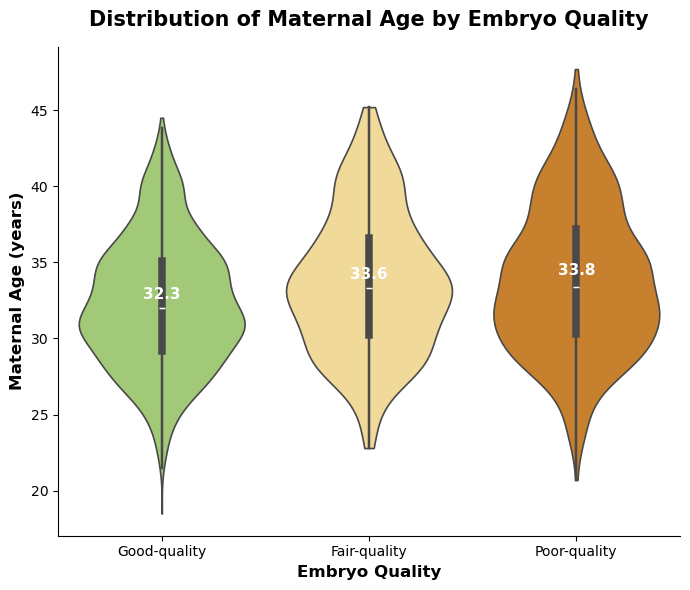

In [27]:
# ==============================
# 8️⃣ 统计不同质量的平均年龄
# ==============================
# 先恢复 fair 胚胎：用同样的规则打上标签
def classify_quality_full(grade_abc):
    exp, icm, te = grade_abc[0], grade_abc[1], grade_abc[2]
    if grade_abc in FAIR_SET:
        return "Fair-quality"
    if int(exp) >= 3 and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    return "Poor-quality"

df_full = df_filtered.copy()
df_full["GradeABC"] = df_full["移植胚胎存活细胞数1"].apply(to_abc_grade)
df_full = df_full[df_full["GradeABC"].notna()].copy()
df_full["Quality"] = df_full["GradeABC"].apply(classify_quality_full)

# 只保留有效年龄
df_full["年龄"] = pd.to_numeric(df_full["年龄"], errors="coerce")
df_full = df_full[df_full["年龄"].notna()]

# 计算平均年龄
mean_age = df_full.groupby("Quality")["年龄"].mean().round(2)

print("\n不同质量胚胎的平均母体年龄：")
for q, age in mean_age.items():
    print(f"  {q}: 平均年龄 = {age} 岁 (n={len(df_full[df_full['Quality']==q])})")


# ==============================
# 9️⃣ 小提琴图：不同质量胚胎的年龄分布
# ==============================
import seaborn as sns
import matplotlib.pyplot as plt

# 只保留三类
df_plot = df_full[df_full["Quality"].isin(["Good-quality", "Fair-quality", "Poor-quality"])].copy()
df_plot["Quality"] = pd.Categorical(
    df_plot["Quality"],
    categories=["Good-quality", "Fair-quality", "Poor-quality"],
    ordered=True
)

# 🎨 定义配色：绿色→黄色→橙色（从好到差）
palette = ["#A1D76A", "#FEE08B", "#E08214"]

plt.figure(figsize=(7, 6))
sns.violinplot(
    data=df_plot,
    x="Quality",
    y="年龄",
    inner="box",        # 在小提琴中显示箱线
    scale="width",      # 使小提琴宽度一致
    cut=0,              # 不延伸超出范围
    linewidth=1.2,
    palette=palette
)

# 均值标注（红点）
mean_ages = df_plot.groupby("Quality")["年龄"].mean()
for i, (q, m) in enumerate(mean_ages.items()):
    plt.text(i, m + 0.3, f"{m:.1f}", ha="center", color="white", fontsize=11, fontweight="bold")

plt.title("Distribution of Maternal Age by Embryo Quality", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Embryo Quality", fontsize=12, fontweight="bold")
plt.ylabel("Maternal Age (years)", fontsize=12, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.savefig(
    "Maternal_age_distribution_by_embryo_quality.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

In [28]:
import pandas as pd

# df_full 已有
# patient_birth = pd.read_csv("PatientBirthDates.csv")
# slide_birth   = pd.read_csv("SlidePatientBirhthDates.csv")

# 1. 类型统一
df_full["女病人ID"] = pd.to_numeric(df_full["女病人ID"], errors="coerce")
patient_birth["PatientID"] = pd.to_numeric(patient_birth["PatientID"], errors="coerce")

# 2. 去重：一位患者一个 PatientIDX
patient_birth_unique = patient_birth.drop_duplicates(subset=["PatientID"])

# 3. 第一次 merge：获得 PatientIDX
df_tmp = df_full.merge(
    patient_birth_unique[["PatientID", "PatientIDX"]],
    left_on="女病人ID",
    right_on="PatientID",
    how="left"
)

# 🔥【关键修复】删除 df_tmp 中已有的 SlideID（可能是过往 merge 引入）
df_tmp = df_tmp.drop(columns=[col for col in df_tmp.columns if "SlideID" in col], errors="ignore")

# 4. slide_birth 去重（每个 PatientIDX 对应一个 slide）
slide_unique = slide_birth.drop_duplicates(subset=["PatientIDX"])

# 5. 第二次 merge：加上 SlideID
df_tmp = df_tmp.merge(
    slide_unique[["PatientIDX", "SlideID"]],
    on="PatientIDX",
    how="left"
)

# 6. 清理中间列
df_tmp = df_tmp.drop(columns=["PatientID", "PatientIDX"], errors="ignore")

# 7. 得到最终结果
df_full = df_tmp

# 8. 筛选 Fair-quality 行
df_fair = df_full[df_full["Quality"] == "Fair-quality"]

df_fair_no_nan = df_fair.dropna(subset=["SlideID"])
print(df_fair_no_nan[["女病人ID", "Quality", "年龄", "SlideID"]])

# df_fair_no_nan.to_csv("/Users/lzz/Downloads/df_fair_no_nan.csv",
#                       index=False, encoding="utf-8-sig")

NameError: name 'patient_birth' is not defined

In [1]:
import pandas as pd
import re
from scipy import stats

# =======================
# 1. 读取三个表
# =======================

df_patient = pd.read_csv("/Users/lzz/Downloads/df_fair_no_nan.csv")
df_pred = pd.read_csv("/Users/lzz/Downloads/embryo_results_2025-12-10.csv")
df_maindb = pd.read_csv("/Users/lzz/Documents/GitHub/IVF_AI/prediction/code/MainDB.csv")


# =======================
# 2. 第一阶段：病人表 + 预测表（按 SlideID 合并）
# =======================

df_pred["SlideID"] = df_pred["embryo_id"].str.extract(
    r"^(D\d{4}\.\d{2}\.\d{2}_S\d+_I\d+_P)"
)

merged = df_patient.merge(df_pred, on="SlideID", how="inner")


# =======================
# 3. 修复 MainDB：RowName → embryo_id
# =======================

df_maindb["embryo_id"] = df_maindb["RowName"].str.replace(
    r"_(\d+)$", r"_WELL\1", regex=True
)

df_maindb = df_maindb.rename(columns={"Quality": "MainDB_Quality"})


# =======================
# 4. 第二阶段：按完整 embryo_id 合并
# =======================

df_maindb_unique = df_maindb.drop_duplicates(subset=["embryo_id"])

merged = merged.merge(
    df_maindb_unique[["embryo_id", "ICM", "TE", "MainDB_Quality"]],
    on="embryo_id",
    how="left"
)


# =======================
# 4.5 按每个病人的「移植数」保留对应行数
#     —— 按 confidence 从高到低
# =======================

merged["confidence_num"] = (
    merged["confidence"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .astype(float)
)

def keep_top_n_by_transfer(group):
    n = int(group["移植数"].iloc[0])
    return (
        group
        .sort_values("confidence_num", ascending=False)
        .head(n)
    )

merged = (
    merged
    .groupby(["女病人ID", "ARTID"], group_keys=False)
    .apply(keep_top_n_by_transfer)
    .reset_index(drop=True)
)


# =======================
# 5. 稳健解析囊胚等级（ICM / TE）
# =======================

merged["囊胚等级_clean"] = (
    merged["囊胚等级"]
    .astype(str)
    .str.upper()
    .str.strip()
)

grade_extracted = merged["囊胚等级_clean"].str.extract(
    r"([ABC])\s*([ABC])\s*$"
)

merged["Grade_ICM"] = grade_extracted[0]
merged["Grade_TE"]  = grade_extracted[1]

merged["ICM_clean"] = merged["ICM"].astype(str).str.upper().str.strip()
merged["TE_clean"]  = merged["TE"].astype(str).str.upper().str.strip()


# =======================
# 6. 筛选：囊胚等级与 MainDB 的 ICM / TE 匹配
# =======================

filtered = merged[
    (merged["Grade_ICM"] == merged["ICM_clean"]) &
    (merged["Grade_TE"]  == merged["TE_clean"])
].copy()


# =======================
# 7. Good / Poor 顺序固定的年龄统计
# =======================

category_order = ["Good", "Poor"]

filtered_gp = filtered[filtered["prediction"].isin(category_order)].copy()

filtered_gp["prediction"] = pd.Categorical(
    filtered_gp["prediction"],
    categories=category_order,
    ordered=True
)

age_summary = (
    filtered_gp
    .groupby("prediction")
    .agg(
        mean_age=("年龄", "mean"),
        n=("年龄", "size")
    )
    .round(2)
)

print("\n📊 Good / Poor 年龄统计（顺序固定）：")
print(age_summary)


# =======================
# 8. 显著性检验：Good vs Poor（Welch t-test）
# =======================

age_good = filtered_gp.loc[
    filtered_gp["prediction"] == "Good", "年龄"
].dropna()

age_poor = filtered_gp.loc[
    filtered_gp["prediction"] == "Poor", "年龄"
].dropna()

t_stat, p_value = stats.ttest_ind(
    age_good,
    age_poor,
    equal_var=False
)

def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

sig_star = p_to_star(p_value)

print("\n🧪 Good vs Poor 年龄差异检验（Welch t-test）")
print(f"Good: n={len(age_good)}, mean={age_good.mean():.2f}")
print(f"Poor: n={len(age_poor)}, mean={age_poor.mean():.2f}")
print(f"p-value = {p_value:.4e} ({sig_star})")


# =======================
# 9. 输出结果
# =======================

filtered_gp.to_csv(
    "merged_by_full_embryo_id.csv",
    index=False,
    encoding="utf-8-sig"
)

age_summary.to_csv(
    "prediction_age_summary_ordered.csv",
    encoding="utf-8-sig"
)

pd.DataFrame({
    "Group1": ["Good"],
    "Group2": ["Poor"],
    "Test": ["Welch t-test"],
    "p_value": [p_value],
    "Significance": [sig_star],
    "n_Good": [len(age_good)],
    "n_Poor": [len(age_poor)]
}).to_csv(
    "prediction_age_significance.csv",
    index=False,
    encoding="utf-8-sig"
)

/Users/lzz/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (



📊 Good / Poor 年龄统计（顺序固定）：
            mean_age    n
prediction               
Good           33.74  105
Poor           34.12  121

🧪 Good vs Poor 年龄差异检验（Welch t-test）
Good: n=105, mean=33.74
Poor: n=121, mean=34.12
p-value = 5.1342e-01 (ns)


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_92548/1310857467.py:72: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(keep_top_n_by_transfer)
/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_92548/1310857467.py:125: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("prediction")


In [50]:
from scipy.stats import fisher_exact
import pandas as pd
import re


df_patient = pd.read_csv("/Users/lzz/Downloads/df_fair_no_nan.csv")
df_pred = pd.read_csv("/Users/lzz/Downloads/embryo_results_2025-12-10.csv")
df_maindb = pd.read_csv("/Users/lzz/Documents/GitHub/IVF_AI/prediction/code/MainDB.csv")


df_pred["SlideID"] = df_pred["embryo_id"].str.extract(
    r"^(D\d{4}\.\d{2}\.\d{2}_S\d+_I\d+_P)"
)

merged = df_patient.merge(df_pred, on="SlideID", how="inner")


df_maindb["embryo_id"] = df_maindb["RowName"].str.replace(
    r"_(\d+)$", r"_WELL\1", regex=True
)

df_maindb = df_maindb.rename(columns={"Quality": "MainDB_Quality"})


df_maindb_unique = df_maindb.drop_duplicates(subset=["embryo_id"])

merged = merged.merge(
    df_maindb_unique[["embryo_id", "ICM", "TE", "MainDB_Quality"]],
    on="embryo_id",
    how="left"
)


merged["囊胚等级_clean"] = (
    merged["囊胚等级"]
    .astype(str)
    .str.upper()
    .str.strip()
)

# 用正则提取末尾两个评分字母（A/B/C）
# 例：4BB -> ICM=B, TE=B
#     4BC -> ICM=B, TE=C
grade_extracted = merged["囊胚等级_clean"].str.extract(r"([ABC])\s*([ABC])\s*$")
merged["Grade_ICM"] = grade_extracted[0]
merged["Grade_TE"]  = grade_extracted[1]

# 同样把 MainDB ICM/TE 清洗成干净的单字母
merged["ICM_clean"] = merged["ICM"].astype(str).str.upper().str.strip()
merged["TE_clean"]  = merged["TE"].astype(str).str.upper().str.strip()


# ================================
# 6. 筛选：囊胚等级与 MainDB 的 ICM/TE 匹配的行
# ================================

filtered = merged[
    (merged["Grade_ICM"] == merged["ICM_clean"]) &
    (merged["Grade_TE"]  == merged["TE_clean"])
].copy()

# 只保留移植数 = 1
filtered = filtered[filtered["移植数"] == 1].copy()

print("筛除移植数=2后剩余行数：", len(filtered))


# ===============================
# Step 1 — 生成 embryo_base_id（去掉 WELL）
# ===============================

filtered["embryo_base_id"] = filtered["embryo_id"].str.extract(
    r"^(D\d{4}\.\d{2}\.\d{2}_S\d+_I\d+_P)"
)


# ===============================
# Step 2 — 因为移植数=1，直接每组保留一个胚胎
# ===============================

result_rows = []

for (pid, art), group in filtered.groupby(["女病人ID", "ARTID"]):

    # 移植数保证都是 1
    unique_embryos = group.drop_duplicates(subset="embryo_base_id")
    
    # 只保留 1 个胚胎（一个移植事件）
    selected = unique_embryos.head(1)
    result_rows.append(selected)

filtered_final = pd.concat(result_rows, ignore_index=True)

print("最终保留的单胚胎移植记录数：", len(filtered_final))


# ===============================
# Step 3 — 计算 Good / Poor 妊娠率
# ===============================

preg_rate = (
    filtered_final
    .groupby("prediction")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)

preg_rate["妊娠概率"] = preg_rate["临床妊娠数"] / preg_rate["总数"] * 100

print("\n===== Good / Poor 妊娠率（移植数=1）=====")
print(preg_rate)


# ===============================
# Step 4 — Two-tailed Fisher's Exact Test
# ===============================

contingency = pd.crosstab(
    filtered_final["prediction"],
    filtered_final["妊娠结局"] == "临床妊娠"
)

print("\n===== 列联表（用于 Fisher’s Test）=====")
print(contingency)

oddsratio, pvalue = fisher_exact(contingency, alternative="two-sided")

print(f"\nOdds Ratio（Good vs Poor）: {oddsratio:.4f}")
print(f"Two-tailed Fisher’s Exact Test p-value: {pvalue:.6f}")

print("\n=== 分析完成（移植数=1） ===")

筛除移植数=2后剩余行数： 569
最终保留的单胚胎移植记录数： 343

===== Good / Poor 妊娠率（移植数=1）=====
  prediction   总数  临床妊娠数       妊娠概率
0       Good  185    114  61.621622
1       Poor  158     78  49.367089

===== 列联表（用于 Fisher’s Test）=====
妊娠结局        False  True 
prediction              
Good           71    114
Poor           80     78

Odds Ratio（Good vs Poor）: 0.6072
Two-tailed Fisher’s Exact Test p-value: 0.028952

=== 分析完成（移植数=1） ===



不同质量胚胎的平均母体 BMI：
  Good-quality: 平均 BMI = 22.25 (n=1610)
  Fair-quality: 平均 BMI = 22.17 (n=475)
  Poor-quality: 平均 BMI = 22.42 (n=589)


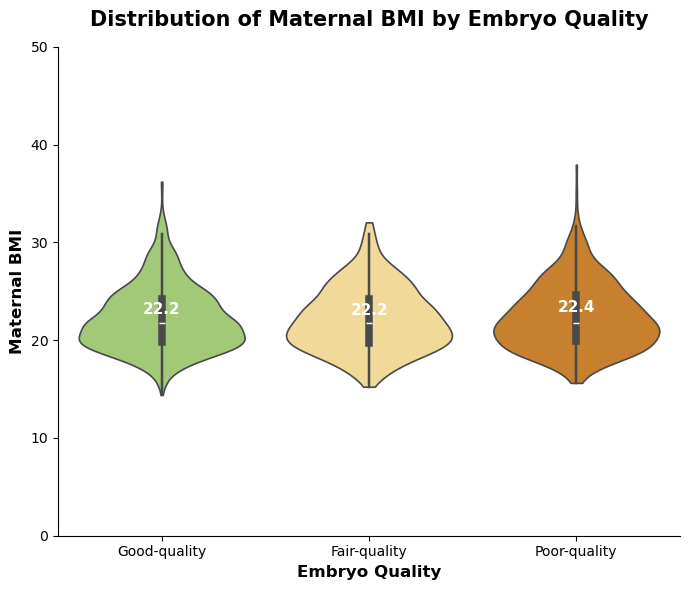

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================
# 0️⃣ 固定顺序（关键）
# ==============================
quality_order = ["Good-quality", "Fair-quality", "Poor-quality"]

# 先把 Quality 设为有序类别（后面 groupby/plot 都会更稳定）
df_full["Quality"] = pd.Categorical(
    df_full["Quality"],
    categories=quality_order,
    ordered=True
)

# ==============================
# 1️⃣ 统计不同质量的平均 BMI
# ==============================
df_full["Bmi(新鲜周期)"] = pd.to_numeric(df_full["Bmi(新鲜周期)"], errors="coerce")
df_bmi = df_full[df_full["Bmi(新鲜周期)"].notna()].copy()

mean_bmi = df_bmi.groupby("Quality", observed=True)["Bmi(新鲜周期)"].mean().round(2)

print("\n不同质量胚胎的平均母体 BMI：")
for q in quality_order:
    if q in mean_bmi.index:
        n = (df_bmi["Quality"] == q).sum()
        print(f"  {q}: 平均 BMI = {mean_bmi.loc[q]} (n={n})")

# ==============================
# 2️⃣ 小提琴图：不同质量胚胎的 BMI 分布
# ==============================
palette = ["#A1D76A", "#FEE08B", "#E08214"]  # Good / Fair / Poor

df_plot = df_bmi[df_bmi["Quality"].isin(quality_order)].copy()

plt.figure(figsize=(7, 6))
sns.violinplot(
    data=df_plot,
    x="Quality",
    y="Bmi(新鲜周期)",
    order=quality_order,         # ✅ 强制顺序
    hue="Quality",               # ✅ 解决 seaborn 未来版本 palette 警告
    palette=palette,
    dodge=False,                 # hue 只是为了配色，不要分组偏移
    inner="box",
    density_norm="width",        # ✅ 替代 scale="width"
    cut=0,
    linewidth=1.2,
    legend=False                 # 不需要图例
)

# 均值标注（按固定顺序）
mean_bmis = df_plot.groupby("Quality", observed=True)["Bmi(新鲜周期)"].mean()
for i, q in enumerate(quality_order):
    if q in mean_bmis.index:
        m = mean_bmis.loc[q]
        plt.text(i, m + 0.1, f"{m:.1f}",
                 ha="center", va="bottom",
                 color="white", fontsize=11, fontweight="bold")

plt.title("Distribution of Maternal BMI by Embryo Quality",
          fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Embryo Quality", fontsize=12, fontweight="bold")
plt.ylabel("Maternal BMI", fontsize=12, fontweight="bold")

plt.ylim(0, 50)  # 你也可以改成更聚焦的范围，比如 (16, 30)

sns.despine()
plt.tight_layout()
plt.savefig(
    "Maternal_BMI_distribution_by_embryo_quality.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

## Cohen’s kappa

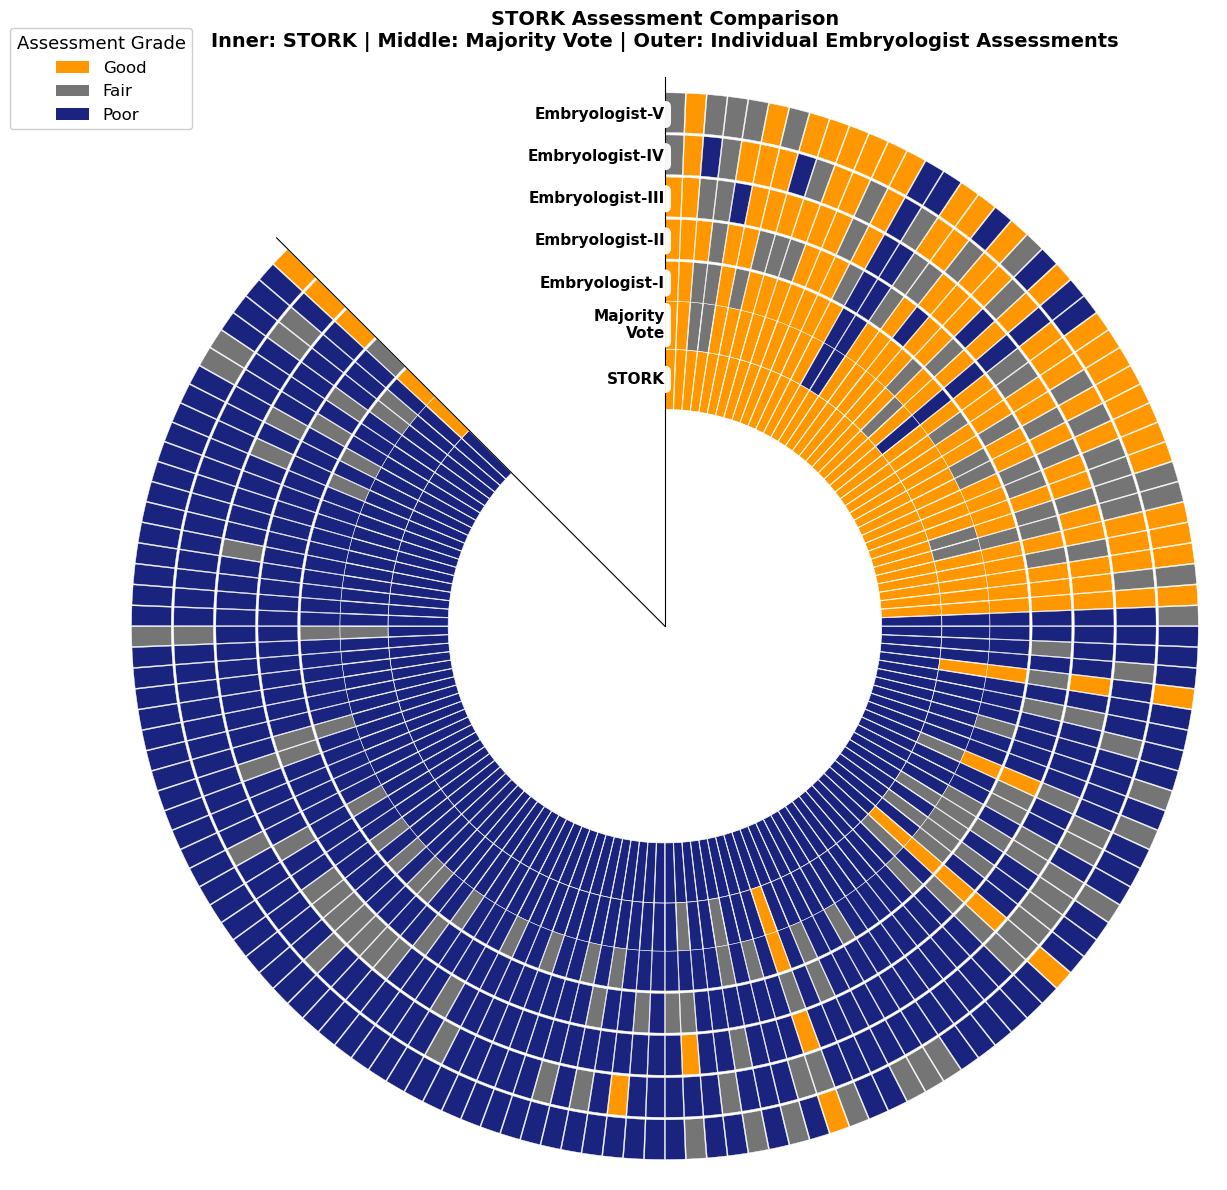

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# =========================
# 1️⃣ 读取和处理数据
# =========================
df = pd.read_excel("/Users/lzz/Downloads/compare_table.xls")
df.rename(columns={df.columns[0]: "EmbryoID"}, inplace=True)

def map_quality(grade):
    """按照标准分类质量"""
    # Already categorized (e.g. STORK column)
    if grade in ["Good", "Poor", "Fair", "Morula"]:
        return grade

    if not isinstance(grade, str):
        return np.nan

    grade = grade.strip().upper()

    if "MORULA" in grade:
        return "Morula"

    if len(grade) < 3:
        return np.nan

    expansion, icm, te = grade[0], grade[1], grade[2]
    grade_3char = grade[:3]

    if grade_3char in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair"
    elif expansion >= "3" and (
        (icm == "A" and te == "A")
        or (icm == "A" and te == "B")
        or (icm == "B" and te == "A")
    ):
        return "Good"
    else:
        return "Poor"


# Embryologist columns
embryologist_cols = ["A", "B", "C", "D", "E"]
for col in embryologist_cols:
    df[col + "_quality"] = df[col].apply(map_quality)

# STORK column
df["STORK_quality"] = df["STORK"].apply(map_quality)

# Majority vote
def majority_vote(row):
    votes = row[[c + "_quality" for c in embryologist_cols]].dropna().values
    if len(votes) == 0:
        return np.nan
    vals, counts = np.unique(votes, return_counts=True)
    return vals[np.argmax(counts)]

df["MajorityVote"] = df.apply(majority_vote, axis=1)

# Sort by STORK prediction
quality_order = {"Good": 0, "Fair": 1, "Poor": 2, "Morula": 3}
df["STORK_sort_order"] = df["STORK_quality"].map(quality_order).fillna(999)
df = df.sort_values("STORK_sort_order").reset_index(drop=True)

# =========================
# 2️⃣ 颜色与映射
# =========================
color_map = {
    "Good": "#FF9800",
    "Poor": "#1A237E",
    "Fair": "#757575"
}

expert_map = {
    "A": "Embryologist-I",
    "B": "Embryologist-II",
    "C": "Embryologist-III",
    "D": "Embryologist-IV",
    "E": "Embryologist-V",
}

# =========================
# 3️⃣ 创建圆环图（留白左上 1/8）
# =========================
fig, ax = plt.subplots(figsize=(14, 12), subplot_kw=dict(projection="polar"))

n_embryos = len(df)
angle_start = np.deg2rad(225)
angle_range = np.deg2rad(315)
angle_per_embryo = angle_range / n_embryos

for embryo_idx, (_, row) in enumerate(df.iterrows()):
    start_angle = angle_start + embryo_idx * angle_per_embryo
    angle = start_angle + angle_per_embryo / 2
    width = angle_per_embryo * 0.95

    # STORK (inner)
    ax.bar(
        angle, 0.5, width=width, bottom=1.8,
        color=color_map.get(row["STORK_quality"], "#CCCCCC"),
        edgecolor="white", linewidth=0.5
    )

    # Majority vote
    ax.bar(
        angle, 0.4, width=width, bottom=2.3,
        color=color_map.get(row["MajorityVote"], "#CCCCCC"),
        edgecolor="white", linewidth=0.5
    )

    # Individual embryologists
    for i, code in enumerate(embryologist_cols):
        r_inner = 2.7 + i * 0.35
        ax.bar(
            angle, 0.33, width=width, bottom=r_inner,
            color=color_map.get(row[code + "_quality"], "#CCCCCC"),
            edgecolor="white", linewidth=0.3
        )

# =========================
# 4️⃣ 标签
# =========================
label_angle = np.deg2rad(225)

ax.text(
    label_angle, 2.05, "STORK",
    ha="right", va="center", fontsize=11, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.95, edgecolor="none"),
)

ax.text(
    label_angle, 2.5, "Majority\nVote",
    ha="right", va="center", fontsize=11, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.95, edgecolor="none"),
)

label_radii = [2.85, 3.20, 3.55, 3.90, 4.25]
for code, radius in zip(embryologist_cols, label_radii):
    ax.text(
        label_angle, radius, expert_map[code],
        ha="right", va="center", fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.95, edgecolor="none"),
    )

# =========================
# 5️⃣ 样式设置
# =========================
ax.set_theta_offset(np.deg2rad(-45))
ax.set_theta_direction(-1)
ax.set_thetamin(225)
ax.set_thetamax(540)

ax.set_xticks([])
ax.set_yticks([])
ax.spines["polar"].set_visible(False)
ax.grid(False)

legend_elems = [
    mpatches.Patch(facecolor=color_map["Good"], label="Good"),
    mpatches.Patch(facecolor=color_map["Fair"], label="Fair"),
    mpatches.Patch(facecolor=color_map["Poor"], label="Poor"),
]

ax.legend(
    handles=legend_elems,
    loc="upper left",
    bbox_to_anchor=(-0.1, 1.05),
    fontsize=12,
    title="Assessment Grade",
    title_fontsize=13,
    framealpha=0.95,
)

plt.title(
    "STORK Assessment Comparison\n"
    "Inner: STORK | Middle: Majority Vote | Outer: Individual Embryologist Assessments",
    fontsize=14, fontweight="bold", pad=20,
)

plt.tight_layout()

# =========================
# 6️⃣ 保存 PNG + PDF（论文推荐用 PDF）
# =========================
out_base = "/Users/lzz/Documents/GitHub/IVF_agent/code/stork_comparison_corrected"
plt.savefig(out_base + ".pdf", bbox_inches="tight")

plt.show()

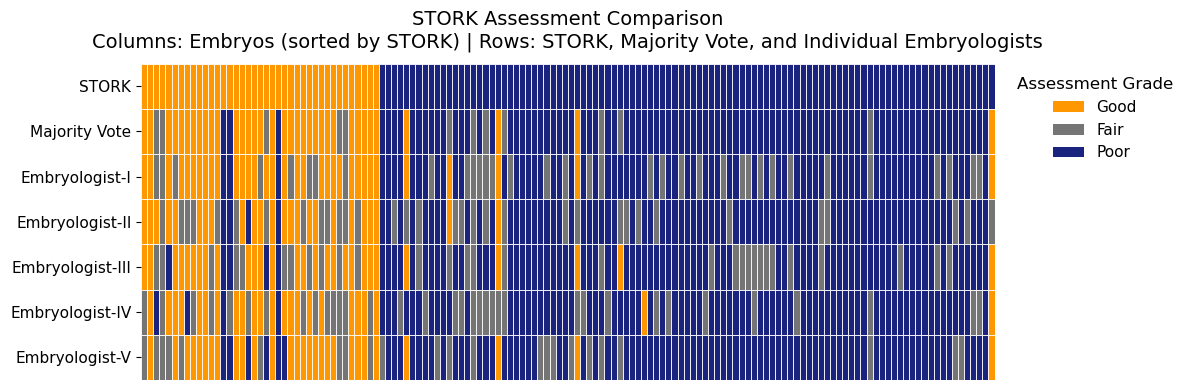

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# =========================
# 1️⃣ 读取和处理数据
# =========================
df = pd.read_excel("/Users/lzz/Downloads/compare_table.xls")
df.rename(columns={df.columns[0]: "EmbryoID"}, inplace=True)

def map_quality(grade):
    if grade in ["Good", "Poor", "Fair", "Morula"]:
        return grade
    if not isinstance(grade, str):
        return np.nan
    grade = grade.strip().upper()
    if "MORULA" in grade:
        return "Morula"
    if len(grade) < 3:
        return np.nan
    expansion, icm, te = grade[0], grade[1], grade[2]
    grade_3char = grade[:3]
    if grade_3char in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair"
    elif expansion >= "3" and (
        (icm == "A" and te == "A")
        or (icm == "A" and te == "B")
        or (icm == "B" and te == "A")
    ):
        return "Good"
    else:
        return "Poor"

embryologist_cols = ["A", "B", "C", "D", "E"]
for col in embryologist_cols:
    df[col + "_quality"] = df[col].apply(map_quality)

df["STORK_quality"] = df["STORK"].apply(map_quality)

def majority_vote(row):
    votes = row[[c + "_quality" for c in embryologist_cols]].dropna().values
    if len(votes) == 0:
        return np.nan
    vals, counts = np.unique(votes, return_counts=True)
    return vals[np.argmax(counts)]

df["MajorityVote"] = df.apply(majority_vote, axis=1)

quality_order = {"Good": 0, "Fair": 1, "Poor": 2, "Morula": 3}
df["STORK_sort_order"] = df["STORK_quality"].map(quality_order).fillna(999)
df = df.sort_values("STORK_sort_order").reset_index(drop=True)

# =========================
# 2️⃣ 颜色映射
# =========================
color_map = {
    "Good": "#FF9800",
    "Fair": "#757575",
    "Poor": "#1A237E",
    "Morula": "#BDBDBD"
}

# 行顺序（自下而上）
row_labels = (
    ["STORK", "Majority Vote"] +
    [f"Embryologist-{i}" for i in ["I", "II", "III", "IV", "V"]]
)

row_sources = (
    ["STORK_quality", "MajorityVote"] +
    [c + "_quality" for c in embryologist_cols]
)

n_rows = len(row_labels)
n_cols = len(df)

# =========================
# 3️⃣ 画矩形图
# =========================
fig, ax = plt.subplots(figsize=(12, 4))

for col_idx, (_, row) in enumerate(df.iterrows()):
    for row_idx, src in enumerate(row_sources):
        quality = row[src]
        color = color_map.get(quality, "#EEEEEE")
        rect = plt.Rectangle(
            (col_idx, row_idx),
            1, 1,
            facecolor=color,
            edgecolor="white",
            linewidth=0.6
        )
        ax.add_patch(rect)

# =========================
# 4️⃣ 坐标轴与标签
# =========================
ax.set_xlim(0, n_cols)
ax.set_ylim(0, n_rows)

ax.set_xticks([])
ax.set_yticks(np.arange(n_rows) + 0.5)
ax.set_yticklabels(row_labels, fontsize=11)

ax.invert_yaxis()  # STORK 在最下

for spine in ax.spines.values():
    spine.set_visible(False)

# =========================
# 5️⃣ 图例
# =========================
legend_elems = [
    mpatches.Patch(facecolor=color_map["Good"], label="Good"),
    mpatches.Patch(facecolor=color_map["Fair"], label="Fair"),
    mpatches.Patch(facecolor=color_map["Poor"], label="Poor"),
]

ax.legend(
    handles=legend_elems,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    title="Assessment Grade",
    frameon=False,
    fontsize=11,
    title_fontsize=12
)

plt.title(
    "STORK Assessment Comparison\n"
    "Columns: Embryos (sorted by STORK) | Rows: STORK, Majority Vote, and Individual Embryologists",
    fontsize=14,
    pad=12
)

plt.tight_layout()

# =========================
# 6️⃣ 保存 PNG + PDF
# =========================
out_base = "/Users/lzz/Documents/GitHub/IVF_agent/code/stork_comparison_rectangular"
plt.savefig(out_base + ".pdf", bbox_inches="tight")

plt.show()

/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 35745 (\N{CJK UNIFIED IDEOGRAPH-8BA1}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 22312 (\N{CJK UNIFIED IDEOGRAPH-5728}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 36825 (\N{CJK UNIFIED IDEOGRAPH-8FD9}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 20123 (\N{CJK UNIFIED IDEOGRAPH-4E9B}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 19987 (\N{CJK UNIFIED IDEOGRAP

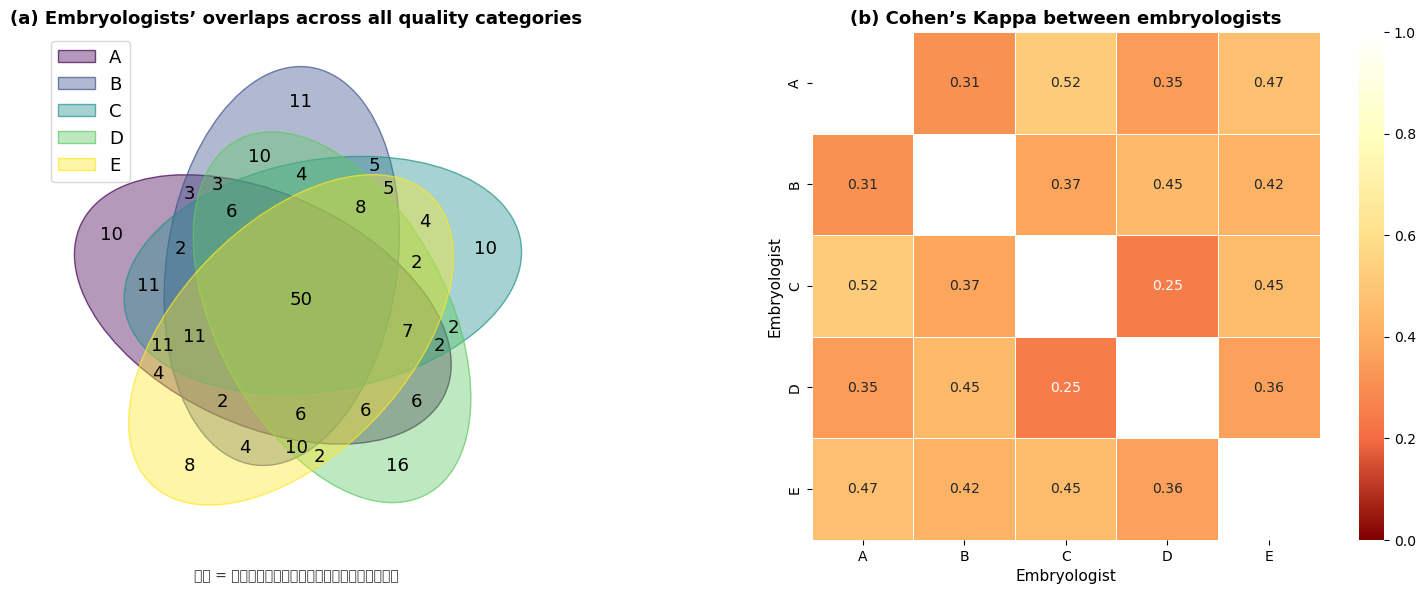

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from sklearn.metrics import cohen_kappa_score
from matplotlib.colors import LinearSegmentedColormap
from venn import venn  

# =========================
# 1️⃣ 读取并映射质量
# =========================
df = pd.read_excel(
    "/Users/lzz/Downloads/compare_table.xls"
)
df.rename(columns={df.columns[0]: "EmbryoID"}, inplace=True)

def map_quality(grade):
    if not isinstance(grade, str):
        return np.nan
    grade = grade.strip().upper()
    if "MORULA" in grade:
        return "Morula"
    if len(grade) < 3:
        return np.nan
    expansion, icm, te = grade[0], grade[1], grade[2]
    g3 = grade[:3]
    if g3 in {"3BB", "4BB", "5BB"}:
        return "Fair"
    if expansion >= "3" and (
        (icm == "A" and te == "A")
        or (icm == "A" and te == "B")
        or (icm == "B" and te == "A")
    ):
        return "Good"
    return "Poor"

experts = ["A", "B", "C", "D", "E"]
for col in experts:
    df[f"{col}_q"] = df[col].apply(map_quality)

# =========================
# 2️⃣ 五专家 Venn 图数据
# =========================
expert_sets = {
    exp: {
        f"{embryo}|{label}"
        for embryo, label in zip(df["EmbryoID"], df[f"{exp}_q"])
        if pd.notna(label)
    }
    for exp in experts
}

# =========================
# 3️⃣ 计算 Cohen’s Kappa 矩阵
# =========================
kappa_matrix = pd.DataFrame(np.eye(len(experts)), index=experts, columns=experts)
for a, b in combinations(experts, 2):
    subset = df[[f"{a}_q", f"{b}_q"]].dropna()
    kappa = np.nan if subset.empty else cohen_kappa_score(subset.iloc[:, 0], subset.iloc[:, 1])
    kappa_matrix.loc[a, b] = kappa
    kappa_matrix.loc[b, a] = kappa

# =========================
# 4️⃣ 自定义颜色映射（高一致性 = 白色）
# =========================
white_hot = LinearSegmentedColormap.from_list(
    "white_hot", ["#7f0000", "#f46d43", "#fdae61", "#fee08b", "#ffffbf", "#ffffff"]
)

# =========================
# 5️⃣ 绘制并排图像 (Supplementary Figure 1)
# =========================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- (a) Venn 图 ---
venn(expert_sets, fmt="{size}", legend_loc="upper left", ax=axes[0])
axes[0].set_title("(a) Embryologists’ overlaps across all quality categories", fontsize=13, fontweight="bold")
axes[0].annotate(
    "计数 = 在这些专家中得到完全相同质量等级的胚胎数",
    xy=(0.5, -0.08), xycoords="axes fraction",
    ha="center", fontsize=10, color="#333333"
)

# --- (b) Cohen’s Kappa 热图 ---
mask = np.eye(len(kappa_matrix), dtype=bool)  # ✅ 只遮住对角线
sns.heatmap(
    kappa_matrix.astype(float),
    annot=True,
    mask=mask,               # 只隐藏对角线上的注释
    cmap=white_hot,
    vmin=0, vmax=1,
    linewidths=0.7, linecolor="white",
    cbar=True,
    square=True,
    ax=axes[1],
    fmt=".2f"
)
axes[1].set_title("(b) Cohen’s Kappa between embryologists", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Embryologist", fontsize=11)
axes[1].set_ylabel("Embryologist", fontsize=11)

plt.tight_layout()
output_pdf = "/Users/lzz/Downloads/Supplementary_Figure_1_expert_agreement.pdf"
plt.savefig(output_pdf, format="pdf", bbox_inches="tight")
plt.show()

In [31]:
# =========================
# 6️⃣ 计算 STORK 与各专家的 Cohen’s kappa（仅 Good / Poor）
# =========================
df["STORK_q"] = df["STORK"].apply(lambda x: str(x).strip().capitalize() if pd.notna(x) else np.nan)

# 仅保留 Good / Poor 的行
df_filtered = df[df["STORK_q"].isin(["Good", "Poor"])].copy()

stork_kappa = {}
for exp in experts:
    subset = df_filtered[[f"{exp}_q", "STORK_q"]].dropna()
    # 同样只考虑专家的 Good / Poor
    subset = subset[subset[f"{exp}_q"].isin(["Good", "Poor"])]
    stork_kappa[exp] = np.nan if subset.empty else cohen_kappa_score(subset.iloc[:, 0], subset.iloc[:, 1])

stork_kappa = pd.Series(stork_kappa, name="STORK_vs_Expert")

# =========================
# 7️⃣ 计算五专家“投票后”结果（只保留 Good / Poor）
# =========================
def majority_vote(row):
    votes = [row[f"{exp}_q"] for exp in experts if pd.notna(row[f"{exp}_q"])]
    if not votes:
        return np.nan
    # 投票时仍计入 Fair，但稍后我们过滤掉它
    return max(set(votes), key=votes.count)

df["Vote_q"] = df.apply(majority_vote, axis=1)

# 仅保留投票结果为 Good/Poor 且 STORK 也有对应值的样本
subset_vote = df[df["Vote_q"].isin(["Good", "Poor"]) & df["STORK_q"].isin(["Good", "Poor"])][["Vote_q", "STORK_q"]]

kappa_vote = np.nan if subset_vote.empty else cohen_kappa_score(subset_vote.iloc[:, 0], subset_vote.iloc[:, 1])

# =========================
# 8️⃣ 输出 kappa
# =========================
print("📊 STORK vs 各专家的 Cohen’s kappa (仅 Good/Poor)：")
print(stork_kappa.round(3))
print("\n📊 STORK vs 投票结果的 Cohen’s kappa (仅 Good/Poor)：", round(kappa_vote, 3))

# =========================
# 9️⃣ Precision / Recall / F1 （Good 为正类）
# =========================
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

subset_vote["Vote_bin"] = subset_vote["Vote_q"].map({"Good": 1, "Poor": 0})
subset_vote["STORK_bin"] = subset_vote["STORK_q"].map({"Good": 1, "Poor": 0})

precision = precision_score(subset_vote["Vote_bin"], subset_vote["STORK_bin"], zero_division=0)
recall = recall_score(subset_vote["Vote_bin"], subset_vote["STORK_bin"], zero_division=0)
f1 = f1_score(subset_vote["Vote_bin"], subset_vote["STORK_bin"], zero_division=0)

cm = confusion_matrix(subset_vote["Vote_bin"], subset_vote["STORK_bin"])
tn, fp, fn, tp = cm.ravel()

# ✅ 统计参与分析的总胚胎数量
n_total = len(subset_vote)

# =========================
# 🔟 输出所有结果
# =========================
print("\n📈 STORK vs 投票结果分类表现（仅 Good/Poor）：")
print(f"Total embryos analyzed: {n_total}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"Confusion matrix: TP={tp}, FP={fp}, FN={fn}, TN={tn}")

📊 STORK vs 各专家的 Cohen’s kappa (仅 Good/Poor)：
A    0.800
B    0.798
C    0.721
D    0.792
E    0.771
Name: STORK_vs_Expert, dtype: float64

📊 STORK vs 投票结果的 Cohen’s kappa (仅 Good/Poor)： 0.843

📈 STORK vs 投票结果分类表现（仅 Good/Poor）：
Total embryos analyzed: 129
Precision: 0.912
Recall:    0.861
F1-score:  0.886
Confusion matrix: TP=31, FP=3, FN=5, TN=90


external validation

In [13]:
zs_data = pd.read_excel("/Users/lzz/Desktop/IVF/embryo_data.xlsx")
zs_data

,病历编号,卵子号,授精时间,Day5_细胞,Day5_评分,Day6_细胞,Day6_评分,Time-lapse_Number,胚胎ID
0,2017-0306,1,22/10/2020 14:12,B,5AB,NaN,NaN,MTL-3246-1453-EA94,MTL-3246-1453-EA94_1
1,2017-0306,2,22/10/2020 14:12,M,NaN,B,3CC,MTL-3246-1453-EA94,MTL-3246-1453-EA94_2
2,2020-0463,1,26/10/2020 14:00,B,3AB,NaN,NaN,MTL-3246-1459-2A99,MTL-3246-1459-2A99_1
3,2020-0463,3,26/10/2020 14:00,C,NaN,C,NaN,MTL-3246-1459-2A99,MTL-3246-1459-2A99_3
4,2020-0463,4,26/10/2020 14:00,M,NaN,M,NaN,MTL-3246-1459-2A99,MTL-3246-1459-2A99_4
...,...,...,...,...,...,...,...,...,...
1995,2023-0016,2,14/12/2024 13:06,B,1,B,4CB,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F_2
1996,2023-0016,3,14/12/2024 13:06,C,NaN,C,NaN,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F_3
1997,2023-0016,4,14/12/2024 13:06,M,NaN,M,NaN,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F_4
1998,2023-0016,5,14/12/2024 13:06,M,NaN,M,NaN,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F_5


In [14]:
import pandas as pd
import numpy as np
import re

pattern = re.compile(r'^[0-9][A-Z]{2}$')

def merge_day5_day6_score(row):
    d5 = row['Day5_评分']
    d6 = row['Day6_评分']

    v5 = isinstance(d5, str) and pattern.match(d5)
    v6 = isinstance(d6, str) and pattern.match(d6)

    if v5 and v6:
        return f"{d5}_{d6}"
    elif v5:
        return d5
    elif v6:
        return d6
    else:
        return np.nan   # 两个都不是 → NA

zs_data['Day5_Day6_评分'] = zs_data.apply(
    merge_day5_day6_score,
    axis=1
)

print(zs_data[['Day5_评分', 'Day6_评分', 'Day5_Day6_评分']].head(10))
print(f"总行数（未过滤）: {len(zs_data)}")
print(f"NA 数量: {zs_data['Day5_Day6_评分'].isna().sum()}")

  Day5_评分 Day6_评分 Day5_Day6_评分
0     5AB     NaN          5AB
1     NaN     3CC          3CC
2     3AB     NaN          3AB
3     NaN     NaN          NaN
4     NaN     NaN          NaN
5     3AB     NaN          3AB
6     NaN     NaN          NaN
7     3BB     NaN          3BB
8     NaN     4BC          4BC
9       0       0          NaN
总行数（未过滤）: 2000
NA 数量: 1108


In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def classify_quality(grade):
    if pd.isna(grade):
        return "Poor-quality"

    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"

    expansion, icm, te = grade[0], grade[1], grade[2]

    if grade in ["3BB", "4BB", "5BB"]:
        return "Fair-quality"

    elif expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"

    # 其余
    else:
        return "Poor-quality"

zs_data["Quality"] = zs_data["Day5_Day6_评分"].apply(
    classify_quality
)

zs_data["胚胎ID"] = (
    zs_data["胚胎ID"]
    .astype(str)
    .str.replace(r"(.+?)_(\d+)$", r"\1/\2DP", regex=True)
)

print(zs_data)
zs_data.to_excel(
    "/Users/lzz/Desktop/IVF/zs_data_filtered.xlsx",
    index=False
)

           病历编号  卵子号              授精时间 Day5_细胞 Day5_评分 Day6_细胞 Day6_评分  \
0     2017-0306    1  22/10/2020 14:12       B     5AB     NaN     NaN   
1     2017-0306    2  22/10/2020 14:12       M     NaN       B     3CC   
2     2020-0463    1  26/10/2020 14:00       B     3AB     NaN     NaN   
3     2020-0463    3  26/10/2020 14:00       C     NaN       C     NaN   
4     2020-0463    4  26/10/2020 14:00       M     NaN       M     NaN   
...         ...  ...               ...     ...     ...     ...     ...   
1995  2023-0016    2  14/12/2024 13:06       B       1       B     4CB   
1996  2023-0016    3  14/12/2024 13:06       C     NaN       C     NaN   
1997  2023-0016    4  14/12/2024 13:06       M     NaN       M     NaN   
1998  2023-0016    5  14/12/2024 13:06       M     NaN       M     NaN   
1999  2023-0016    6  14/12/2024 13:06       7       3     NaN     NaN   

       Time-lapse_Number                    胚胎ID Day5_Day6_评分       Quality  
0     MTL-3246-1453-EA94  MTL-324

In [32]:
zs_data = pd.read_excel("/Users/lzz/Desktop/IVF/zs_data_filtered.xlsx")

In [33]:
zs_data

,病历编号,卵子号,授精时间,Day5_细胞,Day5_评分,Day6_细胞,Day6_评分,Time-lapse_Number,胚胎ID,Day5_Day6_评分,Quality,prediction
0,2017-0306,1,22/10/2020 14:12,B,5AB,NaN,NaN,MTL-3246-1453-EA94,MTL-3246-1453-EA94/1DP,5AB,Good-quality,Poor
1,2017-0306,2,22/10/2020 14:12,M,NaN,B,3CC,MTL-3246-1453-EA94,MTL-3246-1453-EA94/2DP,3CC,Poor-quality,Poor
2,2020-0463,10,26/10/2020 14:00,C,NaN,C,NaN,MTL-3246-1459-2A99,MTL-3246-1459-2A99/10DP,NaN,Poor-quality,Poor
3,2020-0463,11,26/10/2020 14:00,B,3BB,NaN,NaN,MTL-3246-1459-2A99,MTL-3246-1459-2A99/11DP,3BB,Fair-quality,Poor
4,2020-0463,12,26/10/2020 14:00,M,NaN,B,4BC,MTL-3246-1459-2A99,MTL-3246-1459-2A99/12DP,4BC,Poor-quality,Poor
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,2023-0016,2,14/12/2024 13:06,B,1,B,4CB,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F/2DP,4CB,Poor-quality,Poor
1996,2023-0016,3,14/12/2024 13:06,C,NaN,C,NaN,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F/3DP,NaN,Poor-quality,Poor
1997,2023-0016,4,14/12/2024 13:06,M,NaN,M,NaN,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F/4DP,NaN,Poor-quality,Poor
1998,2023-0016,5,14/12/2024 13:06,M,NaN,M,NaN,MTL-3246-1C1F-D77F,MTL-3246-1C1F-D77F/5DP,NaN,Poor-quality,Poor


In [35]:
import pandas as pd
import numpy as np

zs_data.columns = zs_data.columns.astype(str).str.strip()

if "prediction" in zs_data.columns:
    zs_data.rename(columns={"prediction": "Prediction"}, inplace=True)

def classify_quality(grade):
    if pd.isna(grade):
        return "Poor-quality"
    grade = str(grade)
    if len(grade) < 3:
        return "Poor-quality"
    expansion, icm, te = grade[0], grade[1], grade[2]
    if grade in ["3BB", "4BB", "5BB", "6BB"]:
        return "Fair-quality"
    if expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    return "Poor-quality"

zs_data["Quality"] = zs_data["Day5_Day6_评分"].apply(classify_quality)

zs_eval = zs_data[zs_data["Quality"] != "Fair-quality"].copy()

zs_eval["Quality_bin"] = np.where(
    zs_eval["Quality"] == "Good-quality", "Good", "Poor"
)

zs_eval["一致性"] = zs_eval["Quality_bin"] == zs_eval["Prediction"]

print(
    zs_eval[
        ["Day5_Day6_评分", "Quality", "Prediction", "Quality_bin", "一致性"]
    ].head(10)
)

consistency_stats = (
    zs_eval["一致性"]
    .value_counts()
    .rename(index={True: "一致", False: "不一致"})
    .reset_index(name="数量")
)
consistency_stats["比例 (%)"] = (
    consistency_stats["数量"] / consistency_stats["数量"].sum() * 100
)

print(consistency_stats)

TP = ((zs_eval["Quality_bin"] == "Good") & (zs_eval["Prediction"] == "Good")).sum()
TN = ((zs_eval["Quality_bin"] == "Poor") & (zs_eval["Prediction"] == "Poor")).sum()
FP = ((zs_eval["Quality_bin"] == "Poor") & (zs_eval["Prediction"] == "Good")).sum()
FN = ((zs_eval["Quality_bin"] == "Good") & (zs_eval["Prediction"] == "Poor")).sum()

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

confusion = pd.crosstab(
    zs_eval["Quality_bin"],
    zs_eval["Prediction"],
    rownames=["True"],
    colnames=["Predicted"]
)

print(confusion)

accuracy = (TP + TN) / (TP + TN + FP + FN)
sensitivity = TP / (TP + FN) if (TP + FN) > 0 else np.nan
specificity = TN / (TN + FP) if (TN + FP) > 0 else np.nan
precision = TP / (TP + FP) if (TP + FP) > 0 else np.nan

print("Accuracy:", accuracy)
print("Sensitivity (Recall):", sensitivity)
print("Specificity:", specificity)
print("Precision:", precision)


   Day5_Day6_评分       Quality Prediction Quality_bin    一致性
0           5AB  Good-quality       Poor        Good  False
1           3CC  Poor-quality       Poor        Poor   True
2           NaN  Poor-quality       Poor        Poor   True
4           4BC  Poor-quality       Poor        Poor   True
5           3AB  Good-quality       Poor        Good  False
6           NaN  Poor-quality       Poor        Poor   True
7           NaN  Poor-quality       Poor        Poor   True
8           3AB  Good-quality       Poor        Good  False
9           NaN  Poor-quality       Poor        Poor   True
10          4AB  Good-quality       Good        Good   True
   一致性    数量     比例 (%)
0   一致  1498  90.732889
1  不一致   153   9.267111
TP: 93
TN: 1405
FP: 26
FN: 127
Predicted  Good  Poor
True                 
Good         93   127
Poor         26  1405
Accuracy: 0.90732889158086
Sensitivity (Recall): 0.42272727272727273
Specificity: 0.9818308874912649
Precision: 0.7815126050420168


In [39]:
fn_cases = zs_eval[
    (zs_eval["Quality_bin"] == "Good") &
    (zs_eval["Prediction"] == "Poor")
]

print(f"漏检好胚（FN）数量: {len(fn_cases)}")
fn_cases[
    ["胚胎ID", "Day5_Day6_评分", "Quality", "Prediction"]
].head(20)

漏检好胚（FN）数量: 127


,胚胎ID,Day5_Day6_评分,Quality,Prediction
0,MTL-3246-1453-EA94/1DP,5AB,Good-quality,Poor
5,MTL-3246-1459-2A99/1DP,3AB,Good-quality,Poor
8,MTL-3246-1459-2A99/9DP,3AB,Good-quality,Poor
15,MTL-3246-1463-B2C8/7DP,3AB,Good-quality,Poor
39,MTL-3246-146E-4AA0/6DP,3AB,Good-quality,Poor
67,MTL-3246-1491-D81B/2DP,3AB,Good-quality,Poor
76,MTL-3246-14A1-AE8B/9DP,4BA,Good-quality,Poor
82,MTL-3246-14A8-5299/11DP,4BA,Good-quality,Poor
83,MTL-3246-14A8-5299/12DP,4AA,Good-quality,Poor
84,MTL-3246-14A8-5299/13DP,3AB,Good-quality,Poor


In [37]:
fp_cases = zs_eval[
    (zs_eval["Quality_bin"] == "Poor") &
    (zs_eval["Prediction"] == "Good")
]

print(f"误判差胚（FP）数量: {len(fp_cases)}")
fp_cases[
    ["胚胎ID", "Day5_Day6_评分", "Quality", "Prediction"]
].head(27)

误判差胚（FP）数量: 26


,胚胎ID,Day5_Day6_评分,Quality,Prediction
17,MTL-3246-1463-BB59/1DP,5BC,Poor-quality,Good
47,MTL-3246-147B-78AE/5DP,3BC,Poor-quality,Good
53,MTL-3246-147E-13A4/6DP,4BC,Poor-quality,Good
158,MTL-3246-14DA-63EF/4DP,3BC,Poor-quality,Good
182,MTL-3246-1505-DFAB/11DP,NaN,Poor-quality,Good
324,MTL-3246-1560-E88B/4DP,4BC,Poor-quality,Good
413,MTL-3246-1590-2B07/6DP,4CA,Poor-quality,Good
525,MTL-3246-15AE-AA6F/2DP,5BC,Poor-quality,Good
545,MTL-3246-15BA-7E9B/2DP,3CB,Poor-quality,Good
592,MTL-3246-15CA-524C/3DP,NaN,Poor-quality,Good


## CHAID（移植层级：Age + BMI + PC1_p90，病人级PC1）


In [ ]:
import pandas as pd

# 年龄分组合并显示（仅用于展示）
AGE_MERGE = {
    frozenset(["≤30", "31–32", "33–34"]): "≤34",
    frozenset(["35–36", "37–38", "39–40"]): "35–40",
    frozenset(["≥41"]): "≥41",
    frozenset(["31–32", "33–34"]): "31–34",
    frozenset(["≤30"]): "≤30"
}

def merge_age_label(choices):
    if not isinstance(choices, (list, tuple, set)):
        return choices
    s = frozenset([str(x) for x in choices])
    return AGE_MERGE.get(s, choices)

import numpy as np
from CHAID import Tree

# ==============================
# 1️⃣ 读取病人级 PC1 指标
# ==============================
pc1_path = "/Users/lzz/Documents/GitHub/IVF_AI/prediction/code/STORK_lzz_torch/outputs/pc1_cycle_vgg16/pc1_cycle_level.csv"
df_pc1 = pd.read_csv(pc1_path)
df_pc1["patient_id"] = pd.to_numeric(df_pc1["patient_id"], errors="coerce")

# ==============================
# 2️⃣ 移植层级数据（每次移植一条）
# ==============================
transfer = df_filtered.copy()
transfer["Pregnancy"] = (transfer["妊娠结局"] == "临床妊娠").astype(int)
transfer["女病人ID"] = pd.to_numeric(transfer["女病人ID"], errors="coerce")

# 合并病人级 PC1 → 移植层级
merged_tx = transfer.merge(df_pc1, left_on="女病人ID", right_on="patient_id", how="inner")

# ==============================
# 3️⃣ 年龄 / BMI 分组
# ==============================
bins_age = [-np.inf, 30, 32, 34, 36, 38, 40, np.inf]
labels_age = ["≤30", "31–32", "33–34", "35–36", "37–38", "39–40", "≥41"]
merged_tx["AgeGroup"] = pd.cut(merged_tx["年龄"], bins=bins_age, labels=labels_age, right=True)

def bmi_group(bmi):
    if pd.isna(bmi): return None
    if bmi < 18.5: return "Underweight"
    elif bmi < 25: return "Normal"
    else: return "Overweight"

merged_tx["BMIgroup"] = merged_tx["Bmi(新鲜周期)"].apply(bmi_group)

# ==============================
# 4️⃣ PC1_p90 分箱（分位数）
# ==============================
merged_tx["pc1_p90_bin"] = pd.qcut(merged_tx["pc1_p90"], q=10, duplicates="drop").cat.codes

# ==============================
# 5️⃣ CHAID（移植层级）
# ==============================
df_ch = merged_tx.dropna(subset=["Pregnancy", "AgeGroup", "BMIgroup", "pc1_p90_bin"]).copy()

variables = {
    "AgeGroup": "nominal",
    "BMIgroup": "nominal",
    "pc1_p90_bin": "ordinal"
}

chaid_tree_tx = Tree.from_pandas_df(
    df_ch,
    variables,
    "Pregnancy",
    max_depth=5,
    min_child_node_size=30
)

chaid_tree_tx.print_tree()


# ==============================
# 6️⃣ 叶节点妊娠率（含完整路径）
# ==============================
node_map = {n.node_id: n for n in chaid_tree_tx.tree_store}
children = {}
for n in chaid_tree_tx.tree_store:
    if n.parent is not None:
        children.setdefault(n.parent, []).append(n.node_id)

rows = []
for node in chaid_tree_tx.tree_store:
    if not node.split.valid():
        # 回溯父链，拼路径
        conds = []
        cur = node
        while cur.parent is not None:
            parent = node_map.get(cur.parent)
            if parent is None:
                break
            var = parent.split.column  # 变量名
            conds.append(f"{var} in {merge_age_label(cur.choices) if var=="AgeGroup" else cur.choices}")
            cur = parent
        path = " AND ".join(reversed(conds)) if conds else "ROOT"

        counts = node.members
        total = sum(counts.values())
        preg = counts.get(1, 0)
        rate = preg / total * 100 if total > 0 else 0

        rows.append({
            "node_id": node.node_id,
            "path": path,
            "n": total,
            "preg": preg,
            "preg_rate(%)": round(rate, 2)
        })

leaf_tx_df = pd.DataFrame(rows).sort_values("preg_rate(%)", ascending=False)
print("📌 移植层级 CHAID 叶节点妊娠率：")
print(leaf_tx_df)


## 移植层级 CHAID 树可视化（Age + BMI + PC1_p90，病人级PC1）


In [100]:
from graphviz import Digraph

# 年龄分组合并显示（仅用于展示）
AGE_MERGE = {
    frozenset(["≤30", "31–32", "33–34"]): "≤34",
    frozenset(["35–36", "37–38", "39–40"]): "35–40",
    frozenset(["≥41"]): "≥41",
    frozenset(["31–32", "33–34"]): "31–34",
    frozenset(["≤30"]): "≤30"
}

def merge_age_label(choices):
    if not isinstance(choices, (list, tuple, set)):
        return choices
    s = frozenset([str(x) for x in choices])
    return AGE_MERGE.get(s, choices)


# ========= 辅助函数 =========
def success_rate(node_dict):
    total = sum(node_dict.values())
    success = node_dict.get(1, 0)
    rate = 100 * success / total if total > 0 else 0
    return f"{rate:.1f}%"

# ========= 样式定义 =========
styles = {
    "root": {"shape": "ellipse", "style": "filled,bold", "fillcolor": "#FFD166", "color": "#E07A5F", "fontname": "Helvetica-Bold"},
    "split": {"shape": "box", "style": "rounded,filled", "fillcolor": "#B5EAD7", "color": "#4E878C", "fontname": "Helvetica"},
    "leaf": {"shape": "circle", "style": "filled", "fillcolor": "#F9F9F9", "color": "#999999", "fontname": "Helvetica"},
}

# ========= 初始化图 =========
dot = Digraph('CHAID_Tx_PC1p90_Tree', format='pdf')
dot.attr(rankdir='TB', splines='curved', bgcolor='white', sep='0.2', nodesep='0.2', ranksep='0.8')
dot.attr('node', fontsize='7', width='0.6', height='0.4')
dot.attr('edge', fontsize='7')

# ========= 节点映射 =========
node_map = {n.node_id: n for n in chaid_tree_tx.tree_store}
children = {}
for n in chaid_tree_tx.tree_store:
    if n.parent is not None:
        children.setdefault(n.parent, []).append(n.node_id)

# ========= 添加节点 =========
for node_id, node in node_map.items():
    is_root = node.parent is None
    is_leaf = not node.split.valid()

    if is_leaf:
        label = success_rate(node.members)
        dot.node(f"n{node_id}", label, **styles["leaf"])
    else:
        var = node.split.column
        pval = node.split.p
        if is_root:
            label = f"{var}\np={pval:.2e}"
            dot.node(f"n{node_id}", label, **styles["root"])
        else:
            label = f"{var}\np={pval:.2e}"
            dot.node(f"n{node_id}", label, **styles["split"])

# ========= 添加边 =========
for node_id, node in node_map.items():
    for child_id in children.get(node_id, []):
        child = node_map[child_id]
        label = str(merge_age_label(child.choices) if node_map[node_id].split.column=="AgeGroup" else child.choices)
        dot.edge(f"n{node_id}", f"n{child_id}", label=label, color="#4E878C")

# ========= 输出 =========
output_path = dot.render('CHAID_Tx_PC1p90_Tree', view=False)
print(f"✅ PDF saved to: {output_path}")


✅ PDF saved to: CHAID_Tx_PC1p90_Tree.pdf


## Logistic 可视化：OR 森林图 + AUC 条形图
- OR：含 Age/BMI 调整
- AUC：对比 Quality vs PC1_p90


In [72]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

import os

FIG_DIR = "/Users/lzz/Documents/GitHub/IVF_AI/Figures"
os.makedirs(FIG_DIR, exist_ok=True)

# 复用 merged_q（含 Quality=Good/Poor）
# 如果没有 merged_q，请先运行包含 Quality 的那一格

# ========== 1) OR 森林图（含 Age/BMI） ==========
# 指标（包含 Quality）
metrics = ["pc1_p90", "pc1_max", "pc1_mean", "pc1_std", "pc1_median", "n_embryos"]

# 准备数据
merged_q["Age"] = pd.to_numeric(merged_q["Age"], errors="coerce")
merged_q["BMI"] = pd.to_numeric(merged_q["BMI"], errors="coerce")
merged_q["Pregnancy"] = pd.to_numeric(merged_q["Pregnancy"], errors="coerce")

# 标准化连续变量
def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

rows=[]
for col in metrics:
    df = merged_q[["Pregnancy", col, "Age", "BMI"]].dropna().copy()
    if col != "Quality":
        df[col] = zscore(pd.to_numeric(df[col], errors="coerce"))
    df["Age"] = zscore(df["Age"])
    df["BMI"] = zscore(df["BMI"])

    y = df["Pregnancy"].astype(int)
    X = sm.add_constant(df[[col, "Age", "BMI"]])
    m = sm.Logit(y, X).fit(disp=0)

    coef = m.params[col]
    se = m.bse[col]
    or_ = np.exp(coef)
    ci_low = np.exp(coef - 1.96 * se)
    ci_high = np.exp(coef + 1.96 * se)

    rows.append({
        "metric": col,
        "OR": or_,
        "CI_low": ci_low,
        "CI_high": ci_high
    })

forest = pd.DataFrame(rows).sort_values("OR")

plt.figure(figsize=(7, 5))
plt.errorbar(forest["OR"], forest["metric"],
             xerr=[forest["OR"]-forest["CI_low"], forest["CI_high"]-forest["OR"]],
             fmt='o', color='#4E878C', ecolor='#A0C4C7', capsize=3)
plt.axvline(1, color='gray', linestyle='--', linewidth=1)
plt.xscale('log')
plt.xlabel('Odds Ratio (log scale)')
plt.title('Adjusted OR (Age + BMI)')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/logistic_or_forest.pdf")
plt.close()

# ========== 2) AUC 条形图（Quality vs 各 PC 指标） ==========
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

pc_metrics = ["pc1_p90", "pc1_max", "pc1_mean", "pc1_std", "pc1_median", "n_embryos"]

# 统一数据（只保留有 Quality 的子集）
base = merged_q[["Pregnancy", "Age", "BMI", "Quality"] + pc_metrics].dropna().copy()
base["Age"] = zscore(base["Age"])
base["BMI"] = zscore(base["BMI"])
for m in pc_metrics:
    base[m] = zscore(base[m])

y = base["Pregnancy"].astype(int)


def auc_for(cols):
    X = base[cols].values
    clf = LogisticRegression(solver='liblinear')
    clf.fit(X, y)
    pred = clf.predict_proba(X)[:, 1]
    return roc_auc_score(y, pred)

auc_base = auc_for(["Age", "BMI"])
auc_q = auc_for(["Age", "BMI", "Quality"])

rows = [
        {"Model": "Age+BMI", "AUC": auc_base},
    {"Model": "Age+BMI+Quality", "AUC": auc_q},
]

rows.append({"Model": "Age+BMI+pc1_p90+Quality", "AUC": auc_for(["Age", "BMI", "pc1_p90", "Quality"])})

for m in pc_metrics:
    auc_pc = auc_for(["Age", "BMI", m])
    rows.append({"Model": f"Age+BMI+{m}", "AUC": auc_pc})

auc_df = pd.DataFrame(rows).sort_values("AUC", ascending=False)

plt.figure(figsize=(7,4))
plt.bar(auc_df["Model"], auc_df["AUC"], color='#A0C4FF')
plt.ylim(0.6, 0.9)
plt.ylabel('AUC')
plt.title('AUC Comparison')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/auc_comparison.pdf")
plt.close()
